# Perceptrón Multicapa (MLP) para Clasificación de Texto
### Redes Neuronales

Dataset: **20 Newsgroups** (~18.000 posts de foros de Usenet, clasificados en 20 categorías).

Este trabajo extiende la **regresión softmax** a un **MLP** (capas ocultas + no linealidades) sobre vectores TF-IDF. Se reutiliza el mismo pipeline de preprocesamiento, vectorización, tracking (TensorBoard / MLflow) y búsqueda de hiperparámetros (Optuna), de modo que el modelo lineal y el MLP se comparan bajo exactamente el mismo protocolo.

## Objetivos
- Generalizar la clase `SoftmaxRegression` para que acepte **capas ocultas** (1, 2 o 3), con distinta cantidad de neuronas y distintas funciones de activación.
- Buscar con **Optuna** (con **pruning**) la mejor combinación de hiperparámetros de arquitectura, de optimizador (Adam, RMSprop y SGD, con sus momentos de 1.er y 2.º orden), de preprocesamiento, `lr` y `batch_size`.
- Encontrar una combinación de capas y unidades que deje al problema **sobreajustado** (overfitting).
- Analizar los resultados de todos los entrenamientos (performance y tiempos de convergencia), aislar el efecto de cada hiperparámetro y **comparar contra la regresión softmax** con el mismo protocolo, hardware y semillas.

## Estructura
0. Setup · 1. Datos · 2. Preprocesamiento · 3. Vectorización · 4. Modelo · 5. Entrenamiento · 6. Búsqueda con Optuna · 7. Experimento de overfitting · 8. Entrenamiento final · 9. Evaluación · 10. Baseline softmax · 11. Análisis de la búsqueda · 12. Efecto de cada hiperparámetro · 13. Comparación multi-semilla y robustez de la búsqueda · 14. Conclusiones · 15. Exportación de artefactos

## 0. Setup

El notebook está pensado para ejecutarse en un entorno con GPU (por ejemplo, yo ejecuté el notebook en Google Collab con el entorno de ejecución GPU T4). La primera celda instala las dependencias que no vienen preinstaladas. La segunda define las importaciones, la semilla global, el dispositivo y el backend de MLflow.

`SEED` es la semilla principal y `SEEDS` la lista usada para repetir los entrenamientos finales (sección 13). Los resultados tabulares se guardan en `results/`, los logs de TensorBoard en `runs/` y los de MLflow en `mlflow.db`.

In [5]:
!pip install -q optuna mlflow

In [6]:
import os
import re
import gc
import json
import time
import random
import zipfile
import warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

from torch.utils.tensorboard import SummaryWriter
import mlflow
import mlflow.pytorch
import optuna

warnings.filterwarnings("ignore", category=UserWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)

SEED = 42
SEEDS = [42, 123, 2024, 7, 99]
RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)

#Funcion de settear seed
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

#Funcion para liberar memoria del sistema
def free_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("mlp_20newsgroups")

Usando dispositivo: cuda
GPU: Tesla T4


<Experiment: artifact_location='/content/mlruns/1', creation_time=1794200981208, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1794200981208, lifecycle_stage='active', name='mlp_20newsgroups', tags={}, trace_location=None, workspace='default'>

In [7]:
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("punkt")
nltk.download("punkt_tab")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

## 1. Datos: 20 Newsgroups

Se usan las particiones oficiales `train` y `test` de `fetch_20newsgroups`, removiendo encabezados, firmas y citas (`remove=("headers", "footers", "quotes")`). Sin esto el clasificador puede aprovechar metadatos (nombres de usuario, servidores) que identifican al grupo sin depender del contenido del mensaje, lo que infla la accuracy. El conjunto de `test` se reserva para la evaluación final y **no interviene en ninguna decisión de la búsqueda**.

In [8]:
newsgroups_train = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
newsgroups_test = fetch_20newsgroups(subset="test", remove=("headers", "footers", "quotes"))

class_names = newsgroups_train.target_names
NUM_CLASSES = len(class_names)
print(f"Clases ({NUM_CLASSES}):", class_names)
print(f"\nTrain: {len(newsgroups_train.data)} documentos | Test: {len(newsgroups_test.data)} documentos")

print("\n--- Ejemplo de documento ---")
print("Categoría:", class_names[newsgroups_train.target[0]])
print(newsgroups_train.data[0][:500])

Clases (20): ['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']

Train: 11314 documentos | Test: 7532 documentos

--- Ejemplo de documento ---
Categoría: rec.autos
I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a model name, engine specs, years
of production, where this car is made, history, or whatever info you
have on this funky looking car, please e-mail.


## 2. Preprocesamiento configurable

`preprocess_text` tokeniza, pasa a minúsculas y conserva solo tokens alfabéticos. Luego aplica, según los hiperparámetros:

- `remove_stopwords`: elimina las palabras vacías del inglés de NLTK. Es el **único** lugar donde se controlan las stopwords (el vectorizador no recibe una lista fija).
- `normalization`: `"none"` (sin cambios), `"stem"` (Porter, más agresivo, produce raíces no siempre palabras válidas) o `"lemmatize"` (WordNet, más conservador).

La celda siguiente es una verificación sobre una oración de ejemplo para comprobar que cada combinación produce una salida distinta.

In [9]:
STOP_WORDS = set(stopwords.words("english"))
STEMMER = PorterStemmer()
LEMMATIZER = WordNetLemmatizer()


def preprocess_text(text, remove_stopwords, normalization):
    tokens = word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha()]

    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS]

    if normalization == "stem":
        tokens = [STEMMER.stem(t) for t in tokens]
    elif normalization == "lemmatize":
        tokens = [LEMMATIZER.lemmatize(t) for t in tokens]

    return " ".join(tokens)

In [10]:
ejemplo = "The researchers were studying the running processes and stopping conditions of the engines."
for norm in ["none", "stem", "lemmatize"]:
    for rm_sw in [False, True]:
        resultado = preprocess_text(ejemplo, remove_stopwords=rm_sw, normalization=norm)
        print(f"normalization={norm:10s} remove_stopwords={str(rm_sw):5s} -> {resultado}")

normalization=none       remove_stopwords=False -> the researchers were studying the running processes and stopping conditions of the engines
normalization=none       remove_stopwords=True  -> researchers studying running processes stopping conditions engines
normalization=stem       remove_stopwords=False -> the research were studi the run process and stop condit of the engin
normalization=stem       remove_stopwords=True  -> research studi run process stop condit engin
normalization=lemmatize  remove_stopwords=False -> the researcher were studying the running process and stopping condition of the engine
normalization=lemmatize  remove_stopwords=True  -> researcher studying running process stopping condition engine


## 3. Vectorización TF-IDF

Hiperparámetros: `ngram_range` (unigramas o unigramas + bigramas), `max_features` (tamaño máximo del vocabulario) y `min_df` (frecuencia documental mínima de un término).

Decisiones de diseño:
- El vocabulario y los pesos IDF se ajustan **solo con train** y se aplican a validación/test, para no filtrar información.
- Todos los hiperparámetros de vectorización se pasan efectivamente a `TfidfVectorizer`: no hay `stop_words` fijo (eso se controla únicamente en el preprocesamiento) y no se agrega ningún normalizador extra, porque `TfidfVectorizer` ya normaliza cada fila con norma L2 por defecto.

La celda siguiente verifica con un corpus mínimo que los parámetros recibidos se respetan.

In [11]:
def vectorize_data(train_texts, test_texts, ngram_range, max_features, min_df):
    vectorizer = TfidfVectorizer(ngram_range=ngram_range, max_features=max_features, min_df=min_df)
    X_train = vectorizer.fit_transform(train_texts)
    X_test = vectorizer.transform(test_texts)
    return X_train, X_test, vectorizer

In [12]:
_sample_train = ["the cat sat on the mat", "dogs are running in the park", "cats and dogs are pets"]
_sample_test = ["the dog sat on the mat"]
_Xtr, _Xte, _vec = vectorize_data(_sample_train, _sample_test, ngram_range=(1, 1), max_features=50, min_df=2)
print("Shape train:", _Xtr.shape, "| Shape test:", _Xte.shape)
print("Vocabulario:", sorted(_vec.vocabulary_.keys()))
assert set(_vec.vocabulary_) == {"the", "are", "dogs"}, "vectorize_data no respeta los parámetros recibidos"

Shape train: (3, 3) | Shape test: (1, 3)
Vocabulario: ['are', 'dogs', 'the']


## 4. Modelo: MLP (generalización de la regresión softmax)

La clase `MLP` recibe una **lista de tamaños de capas ocultas** (`hidden_units`), una **función de activación** y una tasa de `dropout`:

`x → [Linear → Activación → (Dropout)] × n_capas_ocultas → Linear → logits`

- Con `hidden_units=()` no hay capas ocultas y el modelo es exactamente la regresión softmax (una única `nn.Linear`). Esto permite usar la misma clase, el mismo entrenamiento y la misma búsqueda para el baseline.
- El `forward` devuelve **logits crudos** (sin softmax) porque `CrossEntropyLoss` ya aplica `log_softmax` de forma numéricamente estable.
- Se prueban 7 activaciones: `relu`, `tanh`, `leaky_relu`, `gelu`, `elu`, `silu` y `selu`. Cubren saturantes (`tanh`), rectificadas (`relu`, `leaky_relu`), suaves (`gelu`, `silu`) y autonormalizantes (`selu`, `elu`).
- `dropout=0.0` lo desactiva. Se incluye como hiperparámetro de regularización porque un MLP sobreajusta con facilidad sobre TF-IDF.
- La búsqueda se limita a un máximo de **3 capas ocultas**.

In [13]:
ACTIVATIONS = {
    "relu": lambda: nn.ReLU(),
    "tanh": lambda: nn.Tanh(),
    "leaky_relu": lambda: nn.LeakyReLU(0.01),
    "gelu": lambda: nn.GELU(),
    "elu": lambda: nn.ELU(),
    "silu": lambda: nn.SiLU(),
    "selu": lambda: nn.SELU(),
}


class MLP(nn.Module):
    def __init__(self, input_dim, num_classes, hidden_units=(), activation="relu", dropout=0.0):
        super().__init__()
        layers = []
        prev = input_dim
        for h in hidden_units:
            layers.append(nn.Linear(prev, h))
            layers.append(ACTIVATIONS[activation]())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = h
        self.hidden = nn.Sequential(*layers)
        self.out = nn.Linear(prev, num_classes)

    def forward(self, x):
        return self.out(self.hidden(x))


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

In [14]:
_dummy = torch.randn(4, 50)

_softmax = MLP(50, NUM_CLASSES, hidden_units=())
assert len(_softmax.hidden) == 0 and _softmax(_dummy).shape == (4, NUM_CLASSES)
assert count_params(_softmax) == 50 * NUM_CLASSES + NUM_CLASSES
print("Sin capas ocultas (= regresión softmax):", count_params(_softmax), "parámetros")

for act in ACTIVATIONS:
    m = MLP(50, NUM_CLASSES, hidden_units=(64, 32, 16), activation=act, dropout=0.3)
    assert m(_dummy).shape == (4, NUM_CLASSES)
print("3 capas ocultas (64, 32, 16):", count_params(m), "parámetros | forward OK para todas las activaciones")

Sin capas ocultas (= regresión softmax): 1020 parámetros
3 capas ocultas (64, 32, 16): 6212 parámetros | forward OK para todas las activaciones


## 5. Entrenamiento

Componentes:

1. **`TensorLoader`**: convierte la matriz TF-IDF a un tensor denso y la deja **residente en GPU**, devolviendo mini-batches mezclados en cada época. Evita copias CPU→GPU por batch, que dominarían el tiempo en una búsqueda de cientos de trials.
2. **Optimizador configurable** (`build_optimizer`): Adam (`beta1`, `beta2` = momentos de 1.er y 2.º orden), RMSprop (`alpha` = decaimiento del momento de 2.º orden, `momentum` = 1.er orden) y SGD (`momentum` = 1.er orden, Nesterov opcional). Todos con `weight_decay`.
3. **Pruning**: si se pasa un `trial` de Optuna, en cada época se reporta la accuracy de validación (`trial.report`) y, si el pruner decide que el trial no promete, se corta con `TrialPruned`.
4. **Early stopping** (`patience`) sobre `val_acc`.
5. **Medición de tiempos** con `time.perf_counter()`: tiempo de cada época (entrenamiento + evaluación en validación, sincronizando la GPU antes de medir) y total.
6. **Convergencia**: se define la *época de convergencia* como la primera época en la que `val_acc` queda a menos de `CONV_TOL = 0.005` del máximo alcanzado, y el *tiempo de convergencia* como el tiempo acumulado hasta esa época. Permite comparar cuánto cuesta llegar a un rendimiento equivalente entre configuraciones, no solo cuál rinde más.

Todas las métricas se registran en TensorBoard y MLflow.

In [15]:
class TensorLoader:
    def __init__(self, X, y, batch_size, shuffle):
        self.X = torch.tensor(X.astype(np.float32).toarray(), dtype=torch.float32, device=device)
        self.y = torch.tensor(np.asarray(y), dtype=torch.long, device=device)
        self.batch_size = batch_size
        self.shuffle = shuffle

    def __len__(self):
        return (len(self.y) + self.batch_size - 1) // self.batch_size

    def __iter__(self):
        n = len(self.y)
        if self.shuffle:
            order = torch.randperm(n, device=self.X.device)
        else:
            order = torch.arange(n, device=self.X.device)
        for start in range(0, n, self.batch_size):
            idx = order[start:start + self.batch_size]
            yield self.X[idx], self.y[idx]


def make_loaders(X_train, y_train, X_val, y_val, batch_size):
    train_loader = TensorLoader(X_train, y_train, batch_size, shuffle=True)
    val_loader = TensorLoader(X_val, y_val, batch_size, shuffle=False)
    return train_loader, val_loader


def build_optimizer(model, p):
    name, wd = p["optimizer"], p["weight_decay"]
    if name == "adam":
        return optim.Adam(model.parameters(), lr=p["lr_adam"],
                          betas=(p["beta1"], p["beta2"]), weight_decay=wd)
    if name == "rmsprop":
        return optim.RMSprop(model.parameters(), lr=p["lr_rmsprop"], alpha=p["rms_alpha"],
                             momentum=p["rms_momentum"], weight_decay=wd)
    if name == "sgd":
        nesterov = bool(p["sgd_nesterov"]) and p["sgd_momentum"] > 0
        return optim.SGD(model.parameters(), lr=p["lr_sgd"], momentum=p["sgd_momentum"],
                         nesterov=nesterov, weight_decay=wd)
    raise ValueError(f"Optimizador desconocido: {name}")


def _sync():
    if device.type == "cuda":
        torch.cuda.synchronize()


CONV_TOL = 0.005


def convergence_epoch(val_accs, tol=CONV_TOL):
    target = max(val_accs) - tol
    return next(i + 1 for i, a in enumerate(val_accs) if a >= target)


def train_model(model, train_loader, val_loader, optimizer, epochs, writer=None, run_name="model",
                trial=None, patience=None, verbose=True):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "epoch_time": []}
    best_val_acc, best_epoch, epochs_no_improve = -1.0, 0, 0
    pruned = False
    log_to_mlflow = mlflow.active_run() is not None

    for epoch in range(epochs):
        _sync()
        t0 = time.perf_counter()

        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * xb.size(0)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)
        train_loss, train_acc = running_loss / total, correct / total

        model.eval()
        running_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                logits = model(xb)
                loss = criterion(logits, yb)
                running_loss += loss.item() * xb.size(0)
                correct += (logits.argmax(dim=1) == yb).sum().item()
                total += xb.size(0)
        val_loss, val_acc = running_loss / total, correct / total

        _sync()
        epoch_time = time.perf_counter() - t0
        history["epoch_time"].append(epoch_time)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if verbose:
            print(f"[{run_name}] Epoch {epoch+1}/{epochs} - "
                  f"train_loss: {train_loss:.4f} train_acc: {train_acc:.4f} - "
                  f"val_loss: {val_loss:.4f} val_acc: {val_acc:.4f} - {epoch_time:.2f}s")

        if writer is not None:
            writer.add_scalars("loss", {"train": train_loss, "val": val_loss}, epoch)
            writer.add_scalars("accuracy", {"train": train_acc, "val": val_acc}, epoch)
            writer.add_scalar("epoch_time_s", epoch_time, epoch)
        if log_to_mlflow:
            mlflow.log_metric("train_loss", train_loss, step=epoch)
            mlflow.log_metric("val_loss", val_loss, step=epoch)
            mlflow.log_metric("train_acc", train_acc, step=epoch)
            mlflow.log_metric("val_acc", val_acc, step=epoch)
            mlflow.log_metric("epoch_time_s", epoch_time, step=epoch)

        if val_acc > best_val_acc:
            best_val_acc, best_epoch, epochs_no_improve = val_acc, epoch + 1, 0
        else:
            epochs_no_improve += 1

        if trial is not None:
            trial.report(val_acc, epoch)
            if trial.should_prune():
                pruned = True
                break

        if patience is not None and epochs_no_improve >= patience:
            break

    history["train_time"] = float(sum(history["epoch_time"]))
    history["epochs_run"] = len(history["train_loss"])
    history["best_val_acc"] = best_val_acc
    history["best_epoch"] = best_epoch
    history["final_train_acc"] = history["train_acc"][-1]
    history["final_val_acc"] = history["val_acc"][-1]
    history["conv_epoch"] = convergence_epoch(history["val_acc"])
    history["conv_time"] = float(sum(history["epoch_time"][:history["conv_epoch"]]))

    if trial is not None:
        for k in ["train_time", "epochs_run", "best_epoch", "best_val_acc", "final_train_acc",
                  "final_val_acc", "conv_epoch", "conv_time"]:
            trial.set_user_attr(k, history[k])
    if pruned:
        raise optuna.TrialPruned()
    return history


def evaluate_model(model, loader):
    model.eval()
    preds, labels = [], []
    with torch.no_grad():
        for xb, yb in loader:
            logits = model(xb)
            preds.extend(logits.argmax(dim=1).cpu().numpy())
            labels.extend(yb.cpu().numpy())
    return np.array(preds), np.array(labels)

In [16]:
%load_ext tensorboard

## 6. Búsqueda de hiperparámetros con Optuna (con pruning)

### Diseño de la búsqueda

Se ejecuta **un estudio de Optuna por optimizador** (Adam, RMSprop y SGD), cada uno con el mismo número de trials. Esto resuelve tres problemas de una búsqueda conjunta:

1. **Balance**: con un único estudio, el sampler (TPE) tiende a concentrar trials en el optimizador que rinde mejor al principio y los demás quedan sin explorar.
2. **Comparabilidad**: cada optimizador tiene su propio rango de `lr` y sus propios momentos, así que ninguno queda penalizado por un rango pensado para otro.
3. **Importancia de hiperparámetros bien definida**: los parámetros de cada optimizador existen en todos los trials de su estudio, sin condicionales entre optimizadores.

### Espacio de búsqueda

| Grupo | Hiperparámetro | Valores |
|---|---|---|
| Preprocesamiento | `remove_stopwords` | False, True |
| | `normalization` | none, stem, lemmatize |
| | `ngram_range` | 1gram, 1_2gram |
| | `max_features` | 2000, 5000, 10000, 20000 |
| | `min_df` | 1, 2, 5 |
| Entrenamiento | `batch_size` | 32, 64, 128, 256, 512 |
| Arquitectura | `n_layers` | 1, 2, 3 |
| | `units_l1 … units_lN` (independientes por capa) | 32, 64, 128, 256, 512, 1024, 2048 |
| | `activation` | relu, tanh, leaky_relu, gelu, elu, silu, selu |
| | `dropout` | 0.0 a 0.7 (paso 0.1) |
| Optimizador (común) | `weight_decay` | 1e-8 a 1e-2 (log) |
| Adam | `lr_adam`, `beta1` (1.er momento), `beta2` (2.º momento) | 1e-5–1e-1 (log), 0.5–0.999, 0.9–0.9999 |
| RMSprop | `lr_rmsprop`, `rms_alpha` (2.º momento), `rms_momentum` (1.er momento) | 1e-5–1e-1 (log), 0.8–0.9999, 0–0.95 |
| SGD | `lr_sgd`, `sgd_momentum` (1.er momento), `sgd_nesterov` | 1e-3–30 (log), 0–0.99, True/False |

Los rangos son deliberadamente amplios para que el óptimo caiga en el interior y no sobre un borde. La sección 11 verifica esto con una tabla que cuenta cuántos de los mejores trials quedan cerca de cada límite.

### Pruning
Se usa `MedianPruner`: en cada época se compara la `val_acc` del trial con la mediana de los trials anteriores en esa misma época y se corta si está por debajo. `n_startup_trials` (los primeros trials nunca se podan, para tener referencia) se fija en 1/8 del presupuesto, y con `n_warmup_steps=3` ningún trial se poda en sus primeras 4 épocas. En la sección 11 se cuantifica cuántos trials se podaron y cuánto tiempo se ahorró.

### Optimizaciones de tiempo
- El preprocesamiento (lo más lento) depende solo de `remove_stopwords` y `normalization`: se precalcula una vez para las 6 combinaciones.
- La vectorización TF-IDF se cachea por combinación de hiperparámetros.
- La partición train/validación (80/20 estratificada) es **fija** para todos los trials, así se comparan sobre los mismos datos. El test **no** se usa en la búsqueda.
- Los estudios se guardan en SQLite (`results/optuna_*.db`) y se reanudan automáticamente si la sesión se interrumpe.

In [17]:
print("Precalculando preprocesamiento para las 6 combinaciones posibles (puede tardar unos minutos)...")
preprocessed_cache = {}
for remove_stopwords in [False, True]:
    for normalization in ["none", "stem", "lemmatize"]:
        key = (remove_stopwords, normalization)
        train_proc = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_train.data]
        test_proc = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_test.data]
        preprocessed_cache[key] = (train_proc, test_proc)
        print("  listo:", key)

Precalculando preprocesamiento para las 6 combinaciones posibles (puede tardar unos minutos)...
  listo: (False, 'none')
  listo: (False, 'stem')
  listo: (False, 'lemmatize')
  listo: (True, 'none')
  listo: (True, 'stem')
  listo: (True, 'lemmatize')


Partición fija de entrenamiento/validación utilizada por todos los trials y experimentos de las secciones 6, 7, 11 y 12, y función que devuelve las matrices TF-IDF de esa partición con caché por combinación de hiperparámetros.

In [18]:
y_all = np.array(newsgroups_train.target)
SEARCH_IDX_TR, SEARCH_IDX_VAL = train_test_split(
    np.arange(len(y_all)), test_size=0.2, random_state=SEED, stratify=y_all
)
y_search_tr, y_search_val = y_all[SEARCH_IDX_TR], y_all[SEARCH_IDX_VAL]

_features_cache = {}
FEATURES_CACHE_MAX = 12


def ngram_tuple(name):
    return (1, 1) if name == "1gram" else (1, 2)


def get_search_features(remove_stopwords, normalization, ngram_range, max_features, min_df):
    key = (remove_stopwords, normalization, ngram_range, max_features, min_df)
    if key not in _features_cache:
        train_texts, _ = preprocessed_cache[(remove_stopwords, normalization)]
        tr_texts = [train_texts[i] for i in SEARCH_IDX_TR]
        val_texts = [train_texts[i] for i in SEARCH_IDX_VAL]
        X_tr, X_val, _ = vectorize_data(tr_texts, val_texts, ngram_range, max_features, min_df)
        if len(_features_cache) >= FEATURES_CACHE_MAX:
            _features_cache.pop(next(iter(_features_cache)))
        _features_cache[key] = (X_tr, X_val)
    return _features_cache[key]

### Definición del espacio de búsqueda

`SPACE` y `FLOAT_BOUNDS` centralizan los rangos, de modo que la función que muestrea (`suggest_params`) y el chequeo de bordes de la sección 11 usan exactamente los mismos límites. `suggest_params` recibe el optimizador del estudio (ya no lo muestrea) y devuelve un diccionario con todos los hiperparámetros. Con `use_hidden=False` se omiten los hiperparámetros de arquitectura (baseline softmax). `build_model` construye el modelo correspondiente.

In [19]:
ACTIVATION_NAMES = list(ACTIVATIONS.keys())
OPTIMIZER_NAMES = ["adam", "rmsprop", "sgd"]

SPACE = {
    "batch_size": [32, 64, 128, 256, 512],
    "max_features": [2000, 5000, 10000, 20000],
    "min_df": [1, 2, 5],
    "units": [32, 64, 128, 256, 512, 1024, 2048],
}

FLOAT_BOUNDS = {
    "weight_decay": (1e-8, 1e-2, True),
    "dropout": (0.0, 0.7, False),
    "lr_adam": (1e-5, 1e-1, True),
    "beta1": (0.5, 0.999, False),
    "beta2": (0.9, 0.9999, False),
    "lr_rmsprop": (1e-5, 1e-1, True),
    "rms_alpha": (0.8, 0.9999, False),
    "rms_momentum": (0.0, 0.95, False),
    "lr_sgd": (1e-3, 30.0, True),
    "sgd_momentum": (0.0, 0.99, False),
}


def suggest_float(trial, name):
    low, high, log = FLOAT_BOUNDS[name]
    step = 0.1 if name == "dropout" else None
    return trial.suggest_float(name, low, high, log=log, step=step)


def suggest_params(trial, opt_name, use_hidden=True):
    p = {"optimizer": opt_name}
    p["remove_stopwords"] = trial.suggest_categorical("remove_stopwords", [False, True])
    p["normalization"] = trial.suggest_categorical("normalization", ["none", "stem", "lemmatize"])
    p["ngram_range"] = trial.suggest_categorical("ngram_range", ["1gram", "1_2gram"])
    p["max_features"] = trial.suggest_categorical("max_features", SPACE["max_features"])
    p["min_df"] = trial.suggest_categorical("min_df", SPACE["min_df"])
    p["batch_size"] = trial.suggest_categorical("batch_size", SPACE["batch_size"])

    if use_hidden:
        p["n_layers"] = trial.suggest_int("n_layers", 1, 3)
        for i in range(p["n_layers"]):
            p[f"units_l{i+1}"] = trial.suggest_categorical(f"units_l{i+1}", SPACE["units"])
        p["activation"] = trial.suggest_categorical("activation", ACTIVATION_NAMES)
        p["dropout"] = suggest_float(trial, "dropout")

    p["weight_decay"] = suggest_float(trial, "weight_decay")
    if opt_name == "adam":
        for k in ["lr_adam", "beta1", "beta2"]:
            p[k] = suggest_float(trial, k)
    elif opt_name == "rmsprop":
        for k in ["lr_rmsprop", "rms_alpha", "rms_momentum"]:
            p[k] = suggest_float(trial, k)
    else:
        p["lr_sgd"] = suggest_float(trial, "lr_sgd")
        p["sgd_momentum"] = suggest_float(trial, "sgd_momentum")
        p["sgd_nesterov"] = trial.suggest_categorical("sgd_nesterov", [False, True])
    return p


def hidden_units_from(p):
    return tuple(p[f"units_l{i+1}"] for i in range(p.get("n_layers", 0)))


def build_model(p, input_dim, use_hidden=True):
    if use_hidden:
        return MLP(input_dim, NUM_CLASSES, hidden_units_from(p), p["activation"], p["dropout"])
    return MLP(input_dim, NUM_CLASSES, hidden_units=())

### Función objetivo y ejecución de los estudios

`make_objective` arma la función que Optuna maximiza: muestrea hiperparámetros, entrena con pruning y early stopping (`PATIENCE`) hasta `EPOCHS_SEARCH` épocas, y devuelve la **mejor `val_acc`** alcanzada (equivale a quedarse con el mejor checkpoint). Cada trial queda registrado como un run anidado de MLflow y como una carpeta de TensorBoard (`runs/<búsqueda>/<optimizador>/trial_XXX`). Además de las métricas de rendimiento, cada trial guarda sus tiempos (total, por época, hasta converger) como atributos.

`run_search` crea (o reanuda) un estudio por optimizador con el mismo presupuesto de trials y devuelve un diccionario `{optimizador: estudio}`. `best_of` selecciona el mejor trial entre los tres estudios.

Con `N_TRIALS_PER_OPT = 67` se completan 201 trials en total. El mismo presupuesto se usa luego para el baseline softmax.

In [20]:
EPOCHS_SEARCH = 20
PATIENCE = 5
N_TRIALS_PER_OPT = 67


def make_objective(use_hidden, tag, opt_name, seed):
    def objective(trial):
        p = suggest_params(trial, opt_name, use_hidden)
        set_seed(seed)

        X_tr, X_val = get_search_features(p["remove_stopwords"], p["normalization"],
                                          ngram_tuple(p["ngram_range"]), p["max_features"], p["min_df"])
        train_loader, val_loader = make_loaders(X_tr, y_search_tr, X_val, y_search_val, p["batch_size"])

        model = build_model(p, X_tr.shape[1], use_hidden)
        trial.set_user_attr("n_params", count_params(model))
        optimizer = build_optimizer(model, p)
        writer = SummaryWriter(log_dir=f"runs/{tag}/{opt_name}/trial_{trial.number:03d}")

        pruned = False
        hist = None
        with mlflow.start_run(run_name=f"{tag}_{opt_name}_trial_{trial.number:03d}", nested=True):
            mlflow.log_params({**p, "n_params": count_params(model)})
            try:
                hist = train_model(model, train_loader, val_loader, optimizer, EPOCHS_SEARCH,
                                   writer=writer, run_name=f"{tag}_{opt_name}_{trial.number}",
                                   trial=trial, patience=PATIENCE, verbose=False)
                mlflow.set_tag("optuna_state", "COMPLETE")
                mlflow.log_metrics({"best_val_acc": hist["best_val_acc"],
                                    "train_time_s": hist["train_time"],
                                    "conv_epoch": hist["conv_epoch"],
                                    "conv_time_s": hist["conv_time"]})
            except optuna.TrialPruned:
                pruned = True
                mlflow.set_tag("optuna_state", "PRUNED")
            finally:
                writer.close()

        del train_loader, val_loader, model, optimizer
        free_memory()
        if pruned:
            raise optuna.TrialPruned()
        return hist["best_val_acc"]
    return objective


def run_search(use_hidden, tag, n_trials, seed=SEED):
    studies = {}
    n_startup = max(4, n_trials // 8)
    with mlflow.start_run(run_name=f"optuna_{tag}"):
        for opt_name in OPTIMIZER_NAMES:
            study = optuna.create_study(
                direction="maximize",
                study_name=f"{tag}_{opt_name}",
                storage=f"sqlite:///{RESULTS_DIR}/optuna_{tag}.db",
                load_if_exists=True,
                sampler=optuna.samplers.TPESampler(seed=seed),
                pruner=optuna.pruners.MedianPruner(n_startup_trials=n_startup, n_warmup_steps=3),
            )
            finished = sum(t.state.is_finished() for t in study.trials)
            remaining = n_trials - finished
            if remaining > 0:
                with mlflow.start_run(run_name=f"{tag}_{opt_name}", nested=True):
                    study.optimize(make_objective(use_hidden, tag, opt_name, seed), n_trials=remaining)
                    mlflow.log_params({f"best_{k}": v for k, v in study.best_params.items()})
                    mlflow.log_metric("best_val_acc", study.best_value)
            studies[opt_name] = study
    return studies


def best_of(studies):
    opt_name = max(studies, key=lambda k: studies[k].best_value)
    trial = studies[opt_name].best_trial
    return {**trial.params, "optimizer": opt_name}, trial


def best_by_optimizer(studies):
    return {k: {**s.best_trial.params, "optimizer": k} for k, s in studies.items()}

In [23]:
studies_mlp = run_search(use_hidden=True, tag="mlp_search", n_trials=N_TRIALS_PER_OPT, seed=SEED)

params_mlp, best_trial_mlp = best_of(studies_mlp)
print("Mejor accuracy de validación por optimizador:")
for k, s in studies_mlp.items():
    print(f"  {k:8s} {s.best_value:.4f}  ({len(s.trials)} trials)")
print("\nMejores hiperparámetros:", params_mlp)
print("Mejor accuracy de validación:", round(best_trial_mlp.value, 4))
print("Mejor época del mejor trial:", best_trial_mlp.user_attrs["best_epoch"])

Mejor accuracy de validación por optimizador:
  adam     0.7649  (67 trials)
  rmsprop  0.7631  (67 trials)
  sgd      0.7123  (67 trials)

Mejores hiperparámetros: {'remove_stopwords': True, 'normalization': 'lemmatize', 'ngram_range': '1gram', 'max_features': 20000, 'min_df': 1, 'batch_size': 512, 'n_layers': 1, 'units_l1': 128, 'activation': 'relu', 'dropout': 0.7, 'weight_decay': 9.77571321993535e-08, 'lr_adam': 0.004353156454371769, 'beta1': 0.9120473844865505, 'beta2': 0.9615543556125106, 'optimizer': 'adam'}
Mejor accuracy de validación: 0.7649
Mejor época del mejor trial: 10


## 7. Experimento de overfitting: ¿cuánta capacidad hace falta para sobreajustar?

Se busca una cantidad de capas y unidades ocultas con la que el problema quede **sobreajustado**. Para aislar el efecto de la capacidad:

- Se fija todo lo demás: preprocesamiento y vectorización del mejor trial, `Adam(lr=1e-3)`, activación ReLU, `batch_size=64`, **sin dropout y sin weight decay** (sin regularización).
- Se varía la **profundidad** (1, 2, 3 capas ocultas; nunca más de 3) y el **ancho** (64, 256, 1024 neuronas por capa) en una grilla completa.
- Se entrena un número fijo de épocas, **sin early stopping**, sobre la misma partición train/validación de la búsqueda.

Criterio: el modelo "sobreajusta" cuando su accuracy de entrenamiento supera `OVERFIT_TRAIN_ACC` (0.97, el techo observable en esta grilla; el umbral de 0.99 no se alcanza en ninguna configuración) y, además, su `val_loss` final es al menos `OVERFIT_LOSS_RATIO` (1.5) veces su mínimo, es decir, la pérdida de validación empeora de forma marcada durante el entrenamiento. De todas las configuraciones que cumplen, se elige la de **menor cantidad de parámetros**.

In [26]:
OVERFIT_EPOCHS = 20
OVERFIT_DEPTHS = [1, 2, 3]
OVERFIT_WIDTHS = [64, 256, 1024]
OVERFIT_TRAIN_ACC = 0.97
OVERFIT_LOSS_RATIO = 1.5
OVERFIT_BATCH = 64
OVERFIT_LR = 1e-3

X_tr_of, X_val_of = get_search_features(params_mlp["remove_stopwords"], params_mlp["normalization"],
                                        ngram_tuple(params_mlp["ngram_range"]), params_mlp["max_features"],
                                        params_mlp["min_df"])
train_loader_of, val_loader_of = make_loaders(X_tr_of, y_search_tr, X_val_of, y_search_val,
                                              batch_size=OVERFIT_BATCH)

overfit_rows, overfit_hist = [], {}
for depth in OVERFIT_DEPTHS:
    for width in OVERFIT_WIDTHS:
        set_seed(SEED)
        model_of = MLP(X_tr_of.shape[1], NUM_CLASSES, hidden_units=(width,) * depth, activation="relu", dropout=0.0)
        opt_of = optim.Adam(model_of.parameters(), lr=OVERFIT_LR)
        with mlflow.start_run(run_name=f"overfit_{depth}x{width}"):
            mlflow.log_params({"depth": depth, "width": width, "epochs": OVERFIT_EPOCHS, "lr": OVERFIT_LR,
                               "n_params": count_params(model_of)})
            h = train_model(model_of, train_loader_of, val_loader_of, opt_of, OVERFIT_EPOCHS,
                            run_name=f"{depth}x{width}", patience=None, verbose=False)
        overfit_hist[(depth, width)] = h
        reached = [i + 1 for i, a in enumerate(h["train_acc"]) if a >= OVERFIT_TRAIN_ACC]
        overfit_rows.append({
            "capas": depth, "neuronas/capa": width, "parámetros": count_params(model_of),
            "train_acc final": h["final_train_acc"], "val_acc final": h["final_val_acc"],
            "mejor val_acc": h["best_val_acc"], "mejor época": h["best_epoch"],
            "gap (train - val)": h["final_train_acc"] - h["final_val_acc"],
            f"época con train≥{OVERFIT_TRAIN_ACC}": reached[0] if reached else None,
            "val_loss final / mín": h["val_loss"][-1] / min(h["val_loss"]),
            "val_loss mín → final": f"{min(h['val_loss']):.3f} → {h['val_loss'][-1]:.3f}",
            "tiempo (s)": h["train_time"],
        })
        print(f"{depth}x{width:<5d} train_acc={h['final_train_acc']:.4f} val_acc={h['final_val_acc']:.4f} "
              f"tiempo={h['train_time']:.1f}s")
        del model_of, opt_of
        free_memory()

df_overfit = pd.DataFrame(overfit_rows)
df_overfit.to_csv(f"{RESULTS_DIR}/overfit_grid.csv", index=False)
df_overfit.round(4)

1x64    train_acc=0.9733 val_acc=0.7477 tiempo=5.3s
1x256   train_acc=0.9733 val_acc=0.7477 tiempo=8.5s
1x1024  train_acc=0.9728 val_acc=0.7375 tiempo=24.1s
2x64    train_acc=0.9729 val_acc=0.6964 tiempo=5.8s
2x256   train_acc=0.9724 val_acc=0.7075 tiempo=9.1s
2x1024  train_acc=0.9726 val_acc=0.7291 tiempo=26.2s
3x64    train_acc=0.9722 val_acc=0.5930 tiempo=6.0s
3x256   train_acc=0.9725 val_acc=0.6483 tiempo=9.9s
3x1024  train_acc=0.9734 val_acc=0.6792 tiempo=27.1s


,capas,neuronas/capa,parámetros,train_acc final,val_acc final,mejor val_acc,mejor época,gap (train - val),época con train≥0.97,val_loss final / mín,val_loss mín → final,tiempo (s)
0,1,64,1281364,0.9733,0.7477,0.7627,9,0.2256,11,1.0578,0.866 → 0.916,5.3252
1,1,256,5125396,0.9733,0.7477,0.7609,4,0.2256,7,1.1569,0.855 → 0.989,8.5070
2,1,1024,20501524,0.9728,0.7375,0.7578,2,0.2353,5,1.2511,0.859 → 1.075,24.1497
3,2,64,1285524,0.9729,0.6964,0.7203,5,0.2765,8,1.3950,1.010 → 1.409,5.8069
4,2,256,5191188,0.9724,0.7075,0.7309,2,0.2649,5,1.4046,0.962 → 1.351,9.0554
5,2,1024,21551124,0.9726,0.7291,0.7309,2,0.2435,4,1.3693,0.985 → 1.349,26.1605
6,3,64,1289684,0.9722,0.5930,0.6200,5,0.3791,8,1.9341,1.382 → 2.673,6.0340
7,3,256,5256980,0.9725,0.6483,0.6483,20,0.3242,6,1.8265,1.299 → 2.373,9.8832
8,3,1024,22600724,0.9734,0.6792,0.6871,12,0.2942,5,2.2764,1.165 → 2.651,27.1203


La siguiente celda selecciona la configuración más chica que cumple el criterio de overfitting, la guarda en disco y grafica sus curvas de accuracy y loss junto con un mapa de calor del *gap* entre entrenamiento y validación para toda la grilla.

Configuración más chica que sobreajusta: 3 capa(s) oculta(s) de 64 neuronas (1,289,684 parámetros)
  train_acc=0.9722 | val_acc=0.5930 | gap=0.3791


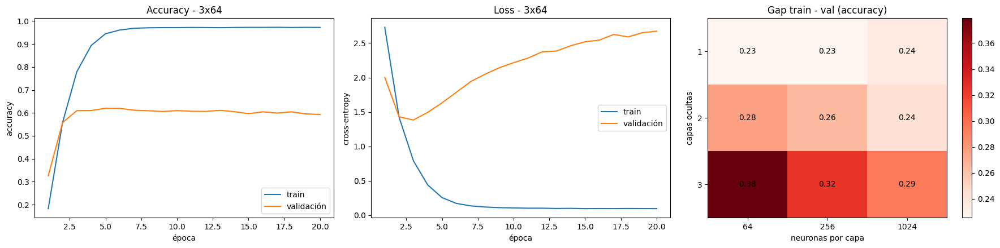

In [27]:
ok = df_overfit[(df_overfit["train_acc final"] >= OVERFIT_TRAIN_ACC)
                & (df_overfit["val_loss final / mín"] >= OVERFIT_LOSS_RATIO)].sort_values("parámetros")
if len(ok):
    chosen = ok.iloc[0]
else:
    print("Ninguna configuración cumple el criterio; se usa la de mayor cociente val_loss final / mín.")
    chosen = df_overfit.sort_values("val_loss final / mín", ascending=False).iloc[0]
c_depth, c_width = int(chosen["capas"]), int(chosen["neuronas/capa"])
print(f"Configuración más chica que sobreajusta: {c_depth} capa(s) oculta(s) de {c_width} neuronas "
      f"({int(chosen['parámetros']):,} parámetros)")
print(f"  train_acc={chosen['train_acc final']:.4f} | "
      f"val_acc={chosen['val_acc final']:.4f} | gap={chosen['gap (train - val)']:.4f}")

overfit_config = {
    "hidden_units": [c_width] * c_depth,
    "activation": "relu",
    "optimizer": "adam",
    "lr": OVERFIT_LR,
    "batch_size": OVERFIT_BATCH,
    "epochs": OVERFIT_EPOCHS,
    "dropout": 0.0,
    "weight_decay": 0.0,
    "preprocessing": {k: params_mlp[k] for k in ["remove_stopwords", "normalization", "ngram_range",
                                                  "max_features", "min_df"]},
    "train_acc": float(chosen["train_acc final"]),
    "val_acc": float(chosen["val_acc final"]),
    "n_params": int(chosen["parámetros"]),
}
with open(f"{RESULTS_DIR}/overfit_config.json", "w") as f:
    json.dump(overfit_config, f, indent=2)

h = overfit_hist[(c_depth, c_width)]
epochs_axis = range(1, len(h["train_acc"]) + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].plot(epochs_axis, h["train_acc"], label="train")
axes[0].plot(epochs_axis, h["val_acc"], label="validación")
axes[0].set(title=f"Accuracy - {c_depth}x{c_width}", xlabel="época", ylabel="accuracy")
axes[0].legend()

axes[1].plot(epochs_axis, h["train_loss"], label="train")
axes[1].plot(epochs_axis, h["val_loss"], label="validación")
axes[1].set(title=f"Loss - {c_depth}x{c_width}", xlabel="época", ylabel="cross-entropy")
axes[1].legend()

gap = df_overfit.pivot(index="capas", columns="neuronas/capa", values="gap (train - val)")
im = axes[2].imshow(gap.values, cmap="Reds", aspect="auto")
axes[2].set_xticks(range(len(gap.columns)), gap.columns)
axes[2].set_yticks(range(len(gap.index)), gap.index)
axes[2].set(title="Gap train - val (accuracy)", xlabel="neuronas por capa", ylabel="capas ocultas")
for i in range(gap.shape[0]):
    for j in range(gap.shape[1]):
        axes[2].text(j, i, f"{gap.values[i, j]:.2f}", ha="center", va="center")
plt.colorbar(im, ax=axes[2])
plt.tight_layout()
plt.show()

## 8. Entrenamiento final del MLP

Con los mejores hiperparámetros de la búsqueda se entrena con **todo** el conjunto de entrenamiento y se evalúa contra el test real, que no se usó en la búsqueda.

La cantidad de épocas **no se elige mirando el test**: se usa la `best_epoch` (mejor época sobre validación) del mejor trial. Durante el entrenamiento se registra la accuracy sobre test por época solo para monitoreo (aparece como `val` en los logs), y el número que se reporta es el del final.

`run_final` recibe la semilla como argumento para poder repetir el protocolo con varias semillas (sección 13). Cachea la vectorización sobre el train completo y solo guarda el modelo en MLflow para la semilla principal.

In [20]:
_final_features_cache = {}


def get_final_features(params):
    key = (params["remove_stopwords"], params["normalization"], params["ngram_range"],
           params["max_features"], params["min_df"])
    if key not in _final_features_cache:
        train_texts, test_texts = preprocessed_cache[(params["remove_stopwords"], params["normalization"])]
        X_train, X_test, _ = vectorize_data(train_texts, test_texts, ngram_tuple(params["ngram_range"]),
                                            params["max_features"], params["min_df"])
        _final_features_cache[key] = (X_train, X_test)
    return _final_features_cache[key]


def run_final(params, use_hidden, tag, epochs, seed=SEED, verbose=True):
    X_train, X_test = get_final_features(params)
    train_loader, test_loader = make_loaders(X_train, newsgroups_train.target,
                                             X_test, newsgroups_test.target, params["batch_size"])

    set_seed(seed)
    model = build_model(params, X_train.shape[1], use_hidden)
    optimizer = build_optimizer(model, params)
    writer = SummaryWriter(log_dir=f"runs/{tag}_final")

    with mlflow.start_run(run_name=f"{tag}_final"):
        mlflow.log_params({**params, "epochs": epochs, "seed": seed, "n_params": count_params(model)})
        history = train_model(model, train_loader, test_loader, optimizer, epochs,
                              writer=writer, run_name=tag, patience=None, verbose=verbose)
        preds, labels = evaluate_model(model, test_loader)
        mlflow.log_metrics({"test_accuracy": accuracy_score(labels, preds),
                            "test_macro_f1": f1_score(labels, preds, average="macro"),
                            "train_time_s": history["train_time"]})
        if seed == SEED:
            try:
                mlflow.pytorch.log_model(model, "model", serialization_format="pickle")
            except Exception as e:
                print("No se pudo loguear el modelo en MLflow:", e)
    writer.close()
    result = {"model": model, "history": history, "preds": preds, "labels": labels,
              "params": params, "n_params": count_params(model)}
    del train_loader, test_loader, optimizer
    free_memory()
    return result

In [21]:
mlflow.end_run()
EPOCHS_FINAL_MLP = best_trial_mlp.user_attrs["best_epoch"]
print("Mejores hiperparámetros MLP:", params_mlp)
print("Épocas del entrenamiento final:", EPOCHS_FINAL_MLP)

res_mlp = run_final(params_mlp, use_hidden=True, tag="mlp", epochs=EPOCHS_FINAL_MLP)

Mejores hiperparámetros MLP: {'remove_stopwords': True, 'normalization': 'lemmatize', 'ngram_range': '1gram', 'max_features': 20000, 'min_df': 1, 'batch_size': 512, 'n_layers': 1, 'units_l1': 128, 'activation': 'relu', 'dropout': 0.7, 'weight_decay': 9.77571321993535e-08, 'lr_adam': 0.004353156454371769, 'beta1': 0.9120473844865505, 'beta2': 0.9615543556125106, 'optimizer': 'adam'}
Épocas del entrenamiento final: 10
[mlp] Epoch 1/10 - train_loss: 2.8598 train_acc: 0.2899 - val_loss: 2.5983 val_acc: 0.5971 - 0.11s
[mlp] Epoch 2/10 - train_loss: 2.1682 train_acc: 0.5814 - val_loss: 1.8443 val_acc: 0.6632 - 0.10s
[mlp] Epoch 3/10 - train_loss: 1.4453 train_acc: 0.6748 - val_loss: 1.3780 val_acc: 0.6818 - 0.08s
[mlp] Epoch 4/10 - train_loss: 1.0347 train_acc: 0.7505 - val_loss: 1.1754 val_acc: 0.6908 - 0.08s
[mlp] Epoch 5/10 - train_loss: 0.8029 train_acc: 0.8026 - val_loss: 1.0852 val_acc: 0.6984 - 0.08s
[mlp] Epoch 6/10 - train_loss: 0.6519 train_acc: 0.8411 - val_loss: 1.0451 val_acc: 0

2026/11/09 05:47:43 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/09 05:47:43 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.
2026/11/09 05:47:44 WARNING mlflow.utils.requirements_utils: Found torch version (2.14.1+cu130) contains a local version label (+cu130). MLflow logged a pip requirement for this package as 'torch==2.14.1' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/11/09 05:47:52 WARNING mlflow.utils.requirements_utils: Found torch version (2.14.1+cu130) contains a local version label

In [22]:
%tensorboard --logdir runs

<IPython.core.display.Javascript object>

## 9. Evaluación final del MLP

Se reporta accuracy, `classification_report` por clase, matriz de confusión y las confusiones más frecuentes entre clases (pares real → predicha con más errores), que permiten ver qué grupos temáticamente cercanos se mezclan.

Accuracy en test (MLP): 0.7023

                          precision    recall  f1-score   support

             alt.atheism       0.51      0.55      0.53       319
           comp.graphics       0.63      0.67      0.65       389
 comp.os.ms-windows.misc       0.65      0.62      0.64       394
comp.sys.ibm.pc.hardware       0.67      0.66      0.67       392
   comp.sys.mac.hardware       0.75      0.70      0.73       385
          comp.windows.x       0.81      0.69      0.74       395
            misc.forsale       0.76      0.77      0.77       390
               rec.autos       0.48      0.81      0.61       396
         rec.motorcycles       0.83      0.73      0.77       398
      rec.sport.baseball       0.89      0.84      0.86       397
        rec.sport.hockey       0.90      0.89      0.89       399
               sci.crypt       0.83      0.73      0.78       396
         sci.electronics       0.63      0.62      0.63       393
                 sci.med       0.84      0.

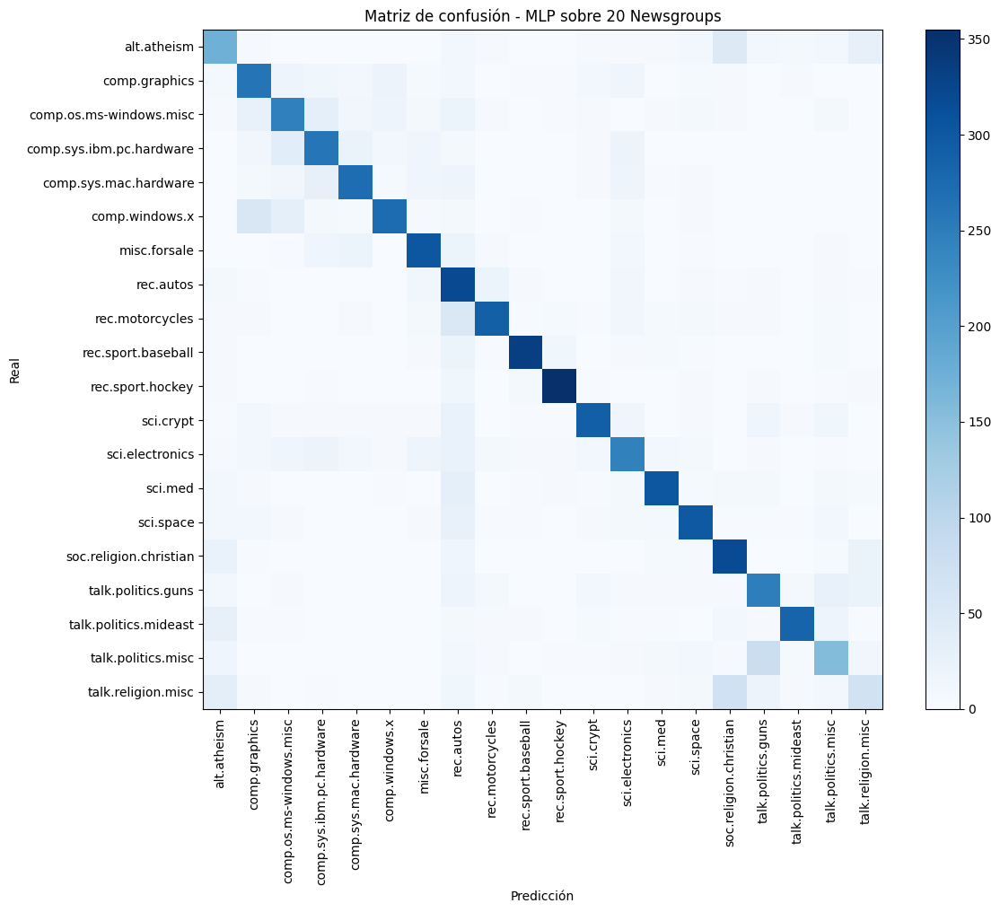

,clase real,predicha como,cantidad
0,talk.politics.misc,talk.politics.guns,80
1,talk.religion.misc,soc.religion.christian,72
2,comp.windows.x,comp.graphics,53
3,rec.motorcycles,rec.autos,50
4,alt.atheism,soc.religion.christian,46
5,comp.sys.ibm.pc.hardware,comp.os.ms-windows.misc,38


In [23]:
def plot_confusion(cm, title):
    plt.figure(figsize=(12, 10))
    plt.imshow(cm, cmap="Blues")
    plt.colorbar()
    plt.xticks(range(NUM_CLASSES), class_names, rotation=90)
    plt.yticks(range(NUM_CLASSES), class_names)
    plt.xlabel("Predicción")
    plt.ylabel("Real")
    plt.title(title)
    plt.tight_layout()
    plt.show()


def top_confusions(cm, k=6):
    off = cm.copy()
    np.fill_diagonal(off, 0)
    rows = []
    for idx in np.argsort(off, axis=None)[::-1][:k]:
        i, j = np.unravel_index(idx, off.shape)
        rows.append((class_names[i], class_names[j], int(off[i, j])))
    return pd.DataFrame(rows, columns=["clase real", "predicha como", "cantidad"])


acc_mlp = accuracy_score(res_mlp["labels"], res_mlp["preds"])
print(f"Accuracy en test (MLP): {acc_mlp:.4f}\n")
print(classification_report(res_mlp["labels"], res_mlp["preds"], target_names=class_names))
cm_mlp = confusion_matrix(res_mlp["labels"], res_mlp["preds"])
plot_confusion(cm_mlp, "Matriz de confusión - MLP sobre 20 Newsgroups")
top_confusions(cm_mlp)

## 10. Baseline: Regresión Softmax con el mismo protocolo

Para que la comparación sea justa, el baseline se obtiene con **el mismo código, el mismo pruner, el mismo espacio de búsqueda (sin hiperparámetros de arquitectura), el mismo número de trials por optimizador, la misma semilla y el mismo hardware** que el MLP. `use_hidden=False` construye `MLP(hidden_units=())`, que es exactamente una capa lineal. El entrenamiento final usa también la `best_epoch` del mejor trial, igual que el MLP, de modo que ninguno de los dos modelos se compara contra una versión sobreentrenada del otro.

In [24]:
studies_softmax = run_search(use_hidden=False, tag="softmax_search", n_trials=N_TRIALS_PER_OPT, seed=SEED)

params_softmax, best_trial_softmax = best_of(studies_softmax)
print("Mejor accuracy de validación por optimizador:")
for k, s in studies_softmax.items():
    print(f"  {k:8s} {s.best_value:.4f}  ({len(s.trials)} trials)")
print("\nMejores hiperparámetros (softmax):", params_softmax)
print("Mejor accuracy de validación:", round(best_trial_softmax.value, 4))

Mejor accuracy de validación por optimizador:
  adam     0.7556  (67 trials)
  rmsprop  0.7415  (67 trials)
  sgd      0.7287  (67 trials)

Mejores hiperparámetros (softmax): {'remove_stopwords': True, 'normalization': 'stem', 'ngram_range': '1gram', 'max_features': 20000, 'min_df': 1, 'batch_size': 64, 'weight_decay': 5.285467724332961e-08, 'lr_adam': 0.004652518863866569, 'beta1': 0.9917008239778888, 'beta2': 0.977142690435861, 'optimizer': 'adam'}
Mejor accuracy de validación: 0.7556


In [25]:
mlflow.end_run()
EPOCHS_FINAL_SOFTMAX = best_trial_softmax.user_attrs["best_epoch"]
res_softmax = run_final(params_softmax, use_hidden=False, tag="softmax", epochs=EPOCHS_FINAL_SOFTMAX)

[softmax] Epoch 1/11 - train_loss: 2.6047 train_acc: 0.5157 - val_loss: 2.2907 val_acc: 0.6225 - 0.27s
[softmax] Epoch 2/11 - train_loss: 1.7334 train_acc: 0.8359 - val_loss: 1.7938 val_acc: 0.6735 - 0.27s
[softmax] Epoch 3/11 - train_loss: 1.1824 train_acc: 0.8834 - val_loss: 1.4891 val_acc: 0.6827 - 0.26s
[softmax] Epoch 4/11 - train_loss: 0.8501 train_acc: 0.9024 - val_loss: 1.3138 val_acc: 0.6872 - 0.26s
[softmax] Epoch 5/11 - train_loss: 0.6443 train_acc: 0.9171 - val_loss: 1.2130 val_acc: 0.6901 - 0.28s
[softmax] Epoch 6/11 - train_loss: 0.5121 train_acc: 0.9298 - val_loss: 1.1559 val_acc: 0.6897 - 0.26s
[softmax] Epoch 7/11 - train_loss: 0.4204 train_acc: 0.9407 - val_loss: 1.1252 val_acc: 0.6896 - 0.26s
[softmax] Epoch 8/11 - train_loss: 0.3544 train_acc: 0.9481 - val_loss: 1.1095 val_acc: 0.6869 - 0.26s
[softmax] Epoch 9/11 - train_loss: 0.3042 train_acc: 0.9544 - val_loss: 1.1024 val_acc: 0.6852 - 0.26s
[softmax] Epoch 10/11 - train_loss: 0.2652 train_acc: 0.9593 - val_loss: 

2026/11/09 06:03:58 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/09 06:03:58 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.
2026/11/09 06:03:58 WARNING mlflow.utils.requirements_utils: Found torch version (2.14.1+cu130) contains a local version label (+cu130). MLflow logged a pip requirement for this package as 'torch==2.14.1' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.


[softmax] Epoch 11/11 - train_loss: 0.2348 train_acc: 0.9623 - val_loss: 1.1036 val_acc: 0.6841 - 0.25s


2026/11/09 06:04:04 WARNING mlflow.utils.requirements_utils: Found torch version (2.14.1+cu130) contains a local version label (+cu130). MLflow logged a pip requirement for this package as 'torch==2.14.1' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.


### Comparación Softmax vs MLP (una semilla)

La tabla resume ambos modelos con el mismo protocolo: rendimiento (validación de la búsqueda y test), tamaño, tiempos y convergencia. La época y el tiempo de convergencia se toman del mejor trial de cada búsqueda (medidos sobre validación, no sobre test). El tiempo de búsqueda es la suma de las duraciones de todos los trials de los tres estudios. La comparación robusta, con varias semillas y su error estándar, está en la sección 13.

In [26]:
def summarize(name, res, studies):
    h = res["history"]
    _, best_trial = best_of(studies)
    all_trials = [t for s in studies.values() for t in s.trials]
    search_time = sum(t.duration.total_seconds() for t in all_trials if t.duration is not None)
    return {
        "modelo": name,
        "val_acc (búsqueda)": best_trial.value,
        "test_acc": accuracy_score(res["labels"], res["preds"]),
        "test_macro_F1": f1_score(res["labels"], res["preds"], average="macro"),
        "train_acc final": h["final_train_acc"],
        "épocas finales": h["epochs_run"],
        "época de convergencia (mejor trial)": best_trial.user_attrs["conv_epoch"],
        "tiempo hasta converger (s, mejor trial)": best_trial.user_attrs["conv_time"],
        "tiempo entrenamiento final (s)": h["train_time"],
        "s/época": float(np.mean(h["epoch_time"])),
        "parámetros": res["n_params"],
        "tiempo de búsqueda (s)": search_time,
        "trials (completos/podados)": f"{sum(t.state.name == 'COMPLETE' for t in all_trials)}/"
                                      f"{sum(t.state.name == 'PRUNED' for t in all_trials)}",
    }


df_compare = pd.DataFrame([summarize("Softmax", res_softmax, studies_softmax),
                           summarize("MLP", res_mlp, studies_mlp)]).set_index("modelo")
df_compare.to_csv(f"{RESULTS_DIR}/comparison_single_seed.csv")
df_compare.T

modelo,Softmax,MLP
val_acc (búsqueda),0.755634,0.764914
test_acc,0.684148,0.702337
test_macro_F1,0.674257,0.692916
train_acc final,0.962348,0.919569
épocas finales,11,10
época de convergencia (mejor trial),6,8
"tiempo hasta converger (s, mejor trial)",1.172787,0.439553
tiempo entrenamiento final (s),2.889994,0.833832
s/época,0.262727,0.083383
parámetros,400020,2562708


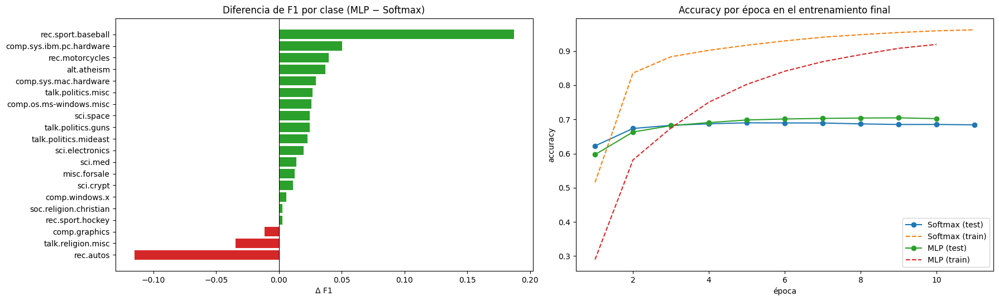

Confusiones más frecuentes - Softmax


,clase real,predicha como,cantidad
0,talk.politics.misc,talk.politics.guns,80
1,talk.religion.misc,soc.religion.christian,55
2,comp.windows.x,comp.graphics,51
3,alt.atheism,soc.religion.christian,49
4,comp.sys.ibm.pc.hardware,comp.os.ms-windows.misc,40
5,comp.os.ms-windows.misc,comp.sys.ibm.pc.hardware,39


Confusiones más frecuentes - MLP


,clase real,predicha como,cantidad
0,talk.politics.misc,talk.politics.guns,80
1,talk.religion.misc,soc.religion.christian,72
2,comp.windows.x,comp.graphics,53
3,rec.motorcycles,rec.autos,50
4,alt.atheism,soc.religion.christian,46
5,comp.sys.ibm.pc.hardware,comp.os.ms-windows.misc,38


In [27]:
f1_soft = f1_score(res_softmax["labels"], res_softmax["preds"], average=None)
f1_mlp = f1_score(res_mlp["labels"], res_mlp["preds"], average=None)

fig, axes = plt.subplots(1, 2, figsize=(18, 5.5))

diff = f1_mlp - f1_soft
order = np.argsort(diff)
axes[0].barh(np.array(class_names)[order], diff[order], color=np.where(diff[order] >= 0, "tab:green", "tab:red"))
axes[0].axvline(0, color="k", lw=0.8)
axes[0].set(title="Diferencia de F1 por clase (MLP − Softmax)", xlabel="Δ F1")

for res, label in [(res_softmax, "Softmax"), (res_mlp, "MLP")]:
    h = res["history"]
    axes[1].plot(range(1, len(h["val_acc"]) + 1), h["val_acc"], marker="o", label=f"{label} (test)")
    axes[1].plot(range(1, len(h["train_acc"]) + 1), h["train_acc"], ls="--", label=f"{label} (train)")
axes[1].set(title="Accuracy por época en el entrenamiento final", xlabel="época", ylabel="accuracy")
axes[1].legend()
plt.tight_layout()
plt.show()

cm_soft = confusion_matrix(res_softmax["labels"], res_softmax["preds"])
print("Confusiones más frecuentes - Softmax")
display(top_confusions(cm_soft))
print("Confusiones más frecuentes - MLP")
display(top_confusions(cm_mlp))

## 11. Análisis de todos los trials del MLP

Esta sección analiza toda la búsqueda, no solo el mejor trial:

1. **Pruning**: cuántos trials se podaron y cuánto tiempo de entrenamiento se ahorró, por optimizador.
2. **Tabla de trials**: los mejores trials con sus hiperparámetros y tiempos.
3. **Efecto por grupo**: rendimiento y tiempos de convergencia según optimizador, activación, profundidad, `batch_size`, vectorización y preprocesamiento.
4. **Learning rate**: rendimiento según el `lr` dentro de cada optimizador (incluye trials podados, usando la mejor `val_acc` que alcanzaron antes del corte, para no sesgar la comparación solo hacia los trials que sobreviven).
5. **Chequeo de bordes**: si los mejores trials se acumulan en los límites del rango, el óptimo podría estar fuera y habría que ampliarlo.
6. **Importancia de hiperparámetros** (fANOVA), calculada por optimizador.

Las medidas de tiempo provienen de `time.perf_counter()` por época. "Época de convergencia" y "tiempo de convergencia" se definen en la sección 5.

In [29]:
def trials_df(studies):
    frames = []
    for opt_name, study in studies.items():
        d = study.trials_dataframe(attrs=("number", "value", "state", "duration", "params", "user_attrs"))
        d["params_optimizer"] = opt_name
        frames.append(d)
    out = pd.concat(frames, ignore_index=True)
    out["duration_s"] = out["duration"].dt.total_seconds()
    out["s_per_epoch"] = out["user_attrs_train_time"] / out["user_attrs_epochs_run"]
    out["perf"] = out["user_attrs_best_val_acc"]
    return out


def pruning_report(df):
    rows = []
    for opt_name, g in df.groupby("params_optimizer"):
        done_g = g[g["state"] == "COMPLETE"]
        prun_g = g[g["state"] == "PRUNED"]
        row = {"optimizador": opt_name, "trials": len(g), "completos": len(done_g), "podados": len(prun_g),
               "tiempo real de podados (s)": np.nan, "tiempo estimado sin poda (s)": np.nan}
        if len(done_g) and len(prun_g):
            epoch_t = prun_g["user_attrs_train_time"] / prun_g["user_attrs_epochs_run"]
            row["tiempo real de podados (s)"] = float(prun_g["user_attrs_train_time"].sum())
            row["tiempo estimado sin poda (s)"] = float((epoch_t * done_g["user_attrs_epochs_run"].mean()).sum())
        rows.append(row)
    out = pd.DataFrame(rows)
    total = {"optimizador": "total", "trials": out["trials"].sum(), "completos": out["completos"].sum(),
             "podados": out["podados"].sum(),
             "tiempo real de podados (s)": out["tiempo real de podados (s)"].sum(),
             "tiempo estimado sin poda (s)": out["tiempo estimado sin poda (s)"].sum()}
    out = pd.concat([out, pd.DataFrame([total])], ignore_index=True)
    out["ahorro (s)"] = out["tiempo estimado sin poda (s)"] - out["tiempo real de podados (s)"]
    out["ahorro (%)"] = 100 * out["ahorro (s)"] / out["tiempo estimado sin poda (s)"]
    return out.round(1)


df_mlp = trials_df(studies_mlp)
df_mlp.to_csv(f"{RESULTS_DIR}/trials_mlp.csv", index=False)
done = df_mlp[df_mlp["state"] == "COMPLETE"].copy()
prun = df_mlp[df_mlp["state"] == "PRUNED"].copy()

print(f"Trials: {len(df_mlp)} | completos: {len(done)} | podados: {len(prun)}")
print(f"Épocas promedio: completos {done['user_attrs_epochs_run'].mean():.1f} | "
      f"podados {prun['user_attrs_epochs_run'].mean():.1f}")
print("\nPruning: el tiempo sin poda se estima como (tiempo por época del trial podado) x (épocas medias de un trial completo)")
display(pruning_report(df_mlp))

print("\nTop 10 trials:")
cols = ["params_optimizer", "number", "value", "user_attrs_best_epoch", "user_attrs_conv_epoch",
        "user_attrs_conv_time", "user_attrs_train_time", "s_per_epoch", "user_attrs_n_params",
        "params_n_layers", "params_activation", "params_dropout", "params_weight_decay",
        "params_batch_size", "params_normalization", "params_ngram_range", "params_max_features"]
top10 = done.sort_values("value", ascending=False)[cols].head(10).round(4)
top10.to_csv(f"{RESULTS_DIR}/top10_trials_mlp.csv", index=False)
top10

Trials: 201 | completos: 129 | podados: 72
Épocas promedio: completos 13.0 | podados 5.7

Pruning: el tiempo sin poda se estima como (tiempo por época del trial podado) x (épocas medias de un trial completo)


,optimizador,trials,completos,podados,tiempo real de podados (s),tiempo estimado sin poda (s),ahorro (s),ahorro (%)
0,adam,67,45,22,9.2,29.0,19.7,68.1
1,rmsprop,67,52,15,58.4,182.0,123.6,67.9
2,sgd,67,32,35,52.0,95.2,43.3,45.4
3,total,201,129,72,119.6,306.2,186.6,60.9



Top 10 trials:


,params_optimizer,number,value,user_attrs_best_epoch,user_attrs_conv_epoch,user_attrs_conv_time,user_attrs_train_time,s_per_epoch,user_attrs_n_params,params_n_layers,params_activation,params_dropout,params_weight_decay,params_batch_size,params_normalization,params_ngram_range,params_max_features
63,adam,63,0.7649,10,8,0.4396,0.8048,0.0537,2562708,1,relu,0.7,0.0,512,lemmatize,1gram,20000
61,adam,61,0.7640,12,10,0.5166,0.8702,0.0512,2562708,1,relu,0.6,0.0,512,lemmatize,1gram,20000
46,adam,46,0.7640,6,6,2.2377,4.0663,0.3697,20501524,1,relu,0.5,0.0,512,none,1gram,20000
127,rmsprop,60,0.7631,10,8,11.9667,22.4205,1.4947,41003028,1,elu,0.2,0.0,128,none,1gram,20000
37,adam,37,0.7631,13,12,0.6856,0.9983,0.0555,2562708,1,tanh,0.4,0.0,512,lemmatize,1gram,20000
132,rmsprop,65,0.7627,14,11,16.4637,28.4342,1.4965,41003028,1,elu,0.2,0.0,128,none,1gram,20000
50,adam,50,0.7627,12,8,0.4184,0.8749,0.0515,2562708,1,relu,0.6,0.0,512,lemmatize,1gram,20000
58,adam,58,0.7627,5,4,0.7568,1.8643,0.1864,10250772,1,relu,0.3,0.0,512,none,1gram,20000
115,rmsprop,48,0.7623,6,4,5.9711,16.4417,1.4947,41003028,1,leaky_relu,0.1,0.0,128,none,1gram,20000
126,rmsprop,59,0.7623,6,4,5.9924,16.4577,1.4962,41003028,1,elu,0.2,0.0,128,none,1gram,20000


In [29]:
def summary_by(df, col, value_col="value"):
    g = df.groupby(col, observed=True).agg(
        n=(value_col, "count"),
        val_acc_media=(value_col, "mean"),
        val_acc_std=(value_col, "std"),
        val_acc_max=(value_col, "max"),
        epoca_conv_media=("user_attrs_conv_epoch", "mean"),
        tiempo_conv_medio_s=("user_attrs_conv_time", "mean"),
        s_por_epoca=("s_per_epoch", "mean"),
        params_medios=("user_attrs_n_params", "mean"),
    )
    return g.round(4)


group_cols = ["params_optimizer", "params_activation", "params_n_layers", "params_batch_size",
              "params_ngram_range", "params_max_features", "params_min_df", "params_normalization",
              "params_remove_stopwords", "params_dropout", "params_units_l1"]
group_tables = {}
for col in group_cols:
    group_tables[col] = summary_by(done, col)
    print(f"--- por {col.replace('params_', '')} (trials completos) ---")
    display(group_tables[col])
pd.concat(group_tables, names=["hiperparámetro", "valor"]).to_csv(f"{RESULTS_DIR}/summary_by_hyperparameter.csv")

--- por optimizer (trials completos) ---


,n,val_acc_media,val_acc_std,val_acc_max,epoca_conv_media,tiempo_conv_medio_s,s_por_epoca,params_medios
params_optimizer,,,,,,,,
adam,45,0.7064,0.1060,0.7649,7.0222,1.8595,0.3142,7.685608e+06
rmsprop,52,0.6957,0.1172,0.7631,6.5577,9.0557,1.5708,2.672800e+07
sgd,32,0.4488,0.2841,0.7123,9.2812,1.7622,0.2417,4.890099e+06


--- por activation (trials completos) ---


,n,val_acc_media,val_acc_std,val_acc_max,epoca_conv_media,tiempo_conv_medio_s,s_por_epoca,params_medios
params_activation,,,,,,,,
elu,21,0.6424,0.2095,0.7631,4.6190,7.2603,1.7859,2.969532e+07
gelu,10,0.5292,0.2790,0.7371,8.5000,9.6844,0.8797,9.324602e+06
leaky_relu,15,0.6208,0.2582,0.7623,6.7333,7.0997,1.5338,2.488224e+07
relu,26,0.6937,0.1113,0.7649,6.7308,2.7141,0.3218,8.064554e+06
selu,23,0.5505,0.2182,0.7123,11.2174,2.6444,0.2819,6.540071e+06
silu,6,0.6033,0.2638,0.7592,6.5000,4.3329,0.6946,1.454050e+07
tanh,28,0.7111,0.1325,0.7631,7.1071,3.4920,0.5439,1.267026e+07


--- por n_layers (trials completos) ---


,n,val_acc_media,val_acc_std,val_acc_max,epoca_conv_media,tiempo_conv_medio_s,s_por_epoca,params_medios
params_n_layers,,,,,,,,
1,107,0.6787,0.1645,0.7649,7.7196,4.9192,0.8141,1.551157e+07
2,16,0.5159,0.2358,0.7543,5.6250,4.1719,0.5666,1.160750e+07
3,6,0.2416,0.1811,0.5139,6.3333,2.9771,1.2300,7.788868e+06


... (12 outputs left out)

--- por dropout (trials completos) ---


,n,val_acc_media,val_acc_std,val_acc_max,epoca_conv_media,tiempo_conv_medio_s,s_por_epoca,params_medios
params_dropout,,,,,,,,
0.0,17,0.6942,0.1492,0.7596,5.4706,10.1946,2.2385,2.955146e+07
0.1,18,0.6525,0.2071,0.7623,6.4444,5.3857,1.0100,1.771947e+07
0.2,21,0.6855,0.2109,0.7631,6.3333,8.3112,1.0464,2.559454e+07
0.3,12,0.7035,0.0758,0.7627,6.7500,2.1243,0.4216,8.145959e+06
0.4,11,0.6698,0.1363,0.7631,9.0909,5.5345,0.5079,1.648785e+07
0.5,17,0.4522,0.2800,0.7640,6.0000,1.3481,0.2421,3.966032e+06
0.6,17,0.6312,0.2219,0.7640,7.5882,1.2559,0.1751,5.315892e+06
0.7,16,0.6348,0.1170,0.7649,12.5000,2.2212,0.4755,6.029408e+06


--- por units_l1 (trials completos) ---


,n,val_acc_media,val_acc_std,val_acc_max,epoca_conv_media,tiempo_conv_medio_s,s_por_epoca,params_medios
params_units_l1,,,,,,,,
32,17,0.6127,0.2259,0.7512,8.7647,1.1109,0.1774,4.436529e+05
64,6,0.4911,0.3408,0.7570,6.1667,1.0385,0.1537,5.880307e+05
128,17,0.6889,0.1984,0.7649,6.0000,0.5099,0.0969,2.440477e+06
256,9,0.5456,0.2033,0.7455,3.1111,1.1422,0.2326,1.784112e+06
512,5,0.5204,0.3341,0.7627,2.2000,0.4606,0.2396,7.178772e+06
1024,30,0.5935,0.1983,0.7640,10.9000,2.5489,0.4308,8.595350e+06
2048,45,0.7096,0.1227,0.7631,6.6667,10.8473,1.8168,3.399604e+07


### Efecto del learning rate por optimizador

El `lr` no es comparable entre optimizadores (SGD con TF-IDF tolera valores órdenes de magnitud mayores que Adam), por eso se analiza dentro de cada uno. Los trials se agrupan en cuartiles de `lr` y se usa la mejor `val_acc` alcanzada por cada trial (incluidos los podados). El gráfico muestra cada trial según su `lr`, distinguiendo los completos de los podados.

--- adam: por cuartil de lr (todos los trials) ---


,n,val_acc_media,val_acc_std,val_acc_max,epoca_conv_media,tiempo_conv_medio_s,s_por_epoca,params_medios
lr_cuartil,,,,,,,,
"(-0.0009211, 0.00093]",17,0.3816,0.2362,0.7318,5.9412,1.8936,0.2839,4.089178e+06
"(0.00093, 0.00247]",17,0.6968,0.0857,0.7640,7.8235,0.5154,0.0808,3.508261e+06
"(0.00247, 0.006]",16,0.7514,0.0192,0.7649,6.0625,0.5740,0.1642,7.970404e+06
"(0.006, 0.0801]",17,0.6698,0.0871,0.7614,4.5882,2.5087,0.4443,7.592489e+06


--- rmsprop: por cuartil de lr (todos los trials) ---


,n,val_acc_media,val_acc_std,val_acc_max,epoca_conv_media,tiempo_conv_medio_s,s_por_epoca,params_medios
lr_cuartil,,,,,,,,
"(-0.0009836, 5.28e-05]",17,0.6667,0.1226,0.7614,7.5882,12.4967,1.4158,2.582273e+07
"(5.28e-05, 0.000125]",17,0.7060,0.1472,0.7631,6.6471,9.3653,1.7467,3.383754e+07
"(0.000125, 0.000285]",16,0.6437,0.2047,0.7623,4.6875,4.5667,1.3915,2.271806e+07
"(0.000285, 0.0801]",17,0.6084,0.1172,0.7234,4.7647,4.8789,1.1918,1.432044e+07


--- sgd: por cuartil de lr (todos los trials) ---


,n,val_acc_media,val_acc_std,val_acc_max,epoca_conv_media,tiempo_conv_medio_s,s_por_epoca,params_medios
lr_cuartil,,,,,,,,
"(0.0009499999999999999, 0.0932]",17,0.1796,0.1499,0.4768,6.3529,1.3128,0.1838,3.906702e+06
"(0.0932, 0.349]",17,0.6156,0.0988,0.7123,12.2941,2.2410,0.1911,4.849543e+06
"(0.349, 1.388]",16,0.4599,0.2677,0.7053,7.5625,1.4174,0.2046,5.488854e+06
"(1.388, 22.615]",17,0.1052,0.0822,0.2996,1.8824,0.5380,0.2894,6.036822e+06


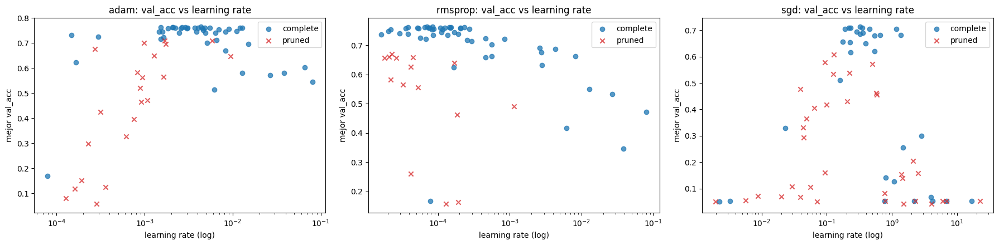

In [30]:
perf_df = df_mlp[df_mlp["perf"].notna()]
lr_tables = {}
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, opt_name in zip(axes, OPTIMIZER_NAMES):
    col = f"params_lr_{opt_name}"
    g = perf_df[perf_df["params_optimizer"] == opt_name].copy()
    g["lr_cuartil"] = pd.qcut(g[col], 4, duplicates="drop")
    lr_tables[opt_name] = summary_by(g, "lr_cuartil", value_col="perf")
    print(f"--- {opt_name}: por cuartil de lr (todos los trials) ---")
    display(lr_tables[opt_name])
    for state, marker, color in [("COMPLETE", "o", "tab:blue"), ("PRUNED", "x", "tab:red")]:
        s = g[g["state"] == state]
        ax.scatter(s[col], s["perf"], marker=marker, color=color, alpha=0.75, label=state.lower())
    ax.set_xscale("log")
    ax.set(title=f"{opt_name}: val_acc vs learning rate", xlabel="learning rate (log)", ylabel="mejor val_acc")
    ax.legend()
plt.tight_layout()
plt.show()
pd.concat(lr_tables, names=["optimizador", "cuartil"]).to_csv(f"{RESULTS_DIR}/summary_by_lr.csv")

### Rendimiento, tiempos y convergencia por grupo

Los boxplots comparan la distribución de `val_acc` (fila superior) y de la **época de convergencia** (fila inferior) según optimizador, activación, profundidad y `batch_size`. Los puntos son trials individuales y el triángulo marca la media. La fila inferior responde cuántas épocas necesita cada configuración para alcanzar su rendimiento.

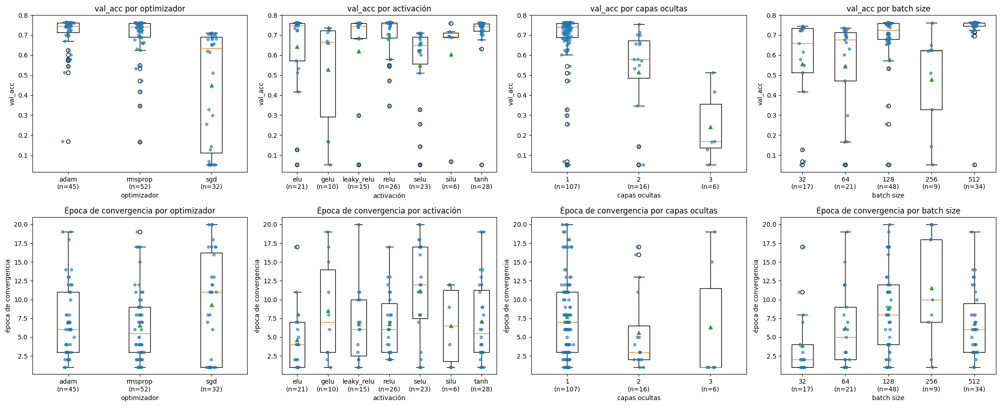

In [31]:
def group_boxplot(ax, df, col, title, xlabel, value_col="value", ylabel="val_acc"):
    cats = sorted(df[col].dropna().unique())
    data = [df.loc[df[col] == c, value_col].dropna().values for c in cats]
    ax.boxplot(data, showmeans=True)
    rng = np.random.default_rng(SEED)
    for i, d in enumerate(data, start=1):
        ax.scatter(rng.normal(i, 0.04, len(d)), d, alpha=0.6, s=18, color="tab:blue", zorder=3)
    ax.set_xticks(range(1, len(cats) + 1))
    ax.set_xticklabels([f"{c}\n(n={len(d)})" for c, d in zip(cats, data)])
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)


panels = [("params_optimizer", "optimizador"), ("params_activation", "activación"),
          ("params_n_layers", "capas ocultas"), ("params_batch_size", "batch size")]
fig, axes = plt.subplots(2, 4, figsize=(22, 9))
for j, (col, label) in enumerate(panels):
    group_boxplot(axes[0, j], done, col, f"val_acc por {label}", label)
    group_boxplot(axes[1, j], done, col, f"Época de convergencia por {label}", label,
                  value_col="user_attrs_conv_epoch", ylabel="época de convergencia")
plt.tight_layout()
plt.show()

### Vectorización y preprocesamiento

Mismo análisis para los hiperparámetros de vectorización (`ngram_range`, `max_features`, `min_df`) y de preprocesamiento (`normalization`, `remove_stopwords`). Interesa tanto la accuracy como el costo: más `max_features` y bigramas agrandan la entrada y, con ella, la primera capa lineal.

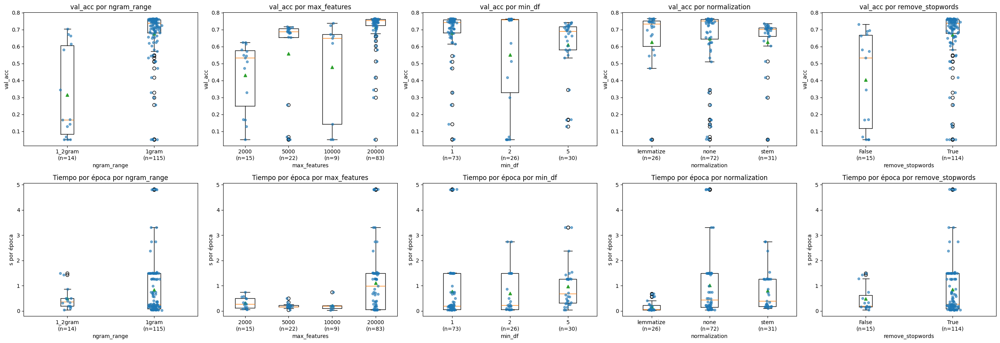

In [32]:
panels = [("params_ngram_range", "ngram_range"), ("params_max_features", "max_features"),
          ("params_min_df", "min_df"), ("params_normalization", "normalization"),
          ("params_remove_stopwords", "remove_stopwords")]
fig, axes = plt.subplots(2, 5, figsize=(26, 9))
for j, (col, label) in enumerate(panels):
    group_boxplot(axes[0, j], done, col, f"val_acc por {label}", label)
    group_boxplot(axes[1, j], done, col, f"Tiempo por época por {label}", label,
                  value_col="s_per_epoch", ylabel="s por época")
plt.tight_layout()
plt.show()

### Rendimiento vs costo e historia de la búsqueda

Fila superior: `val_acc` contra tiempo de entrenamiento, contra tiempo de convergencia y contra tamaño del modelo, por optimizador. Fila inferior: historia de cada estudio (`val_acc` de cada trial, la mejor hasta el momento y los trials podados marcados con una cruz), que muestra si la búsqueda seguía mejorando o ya se había estabilizado.

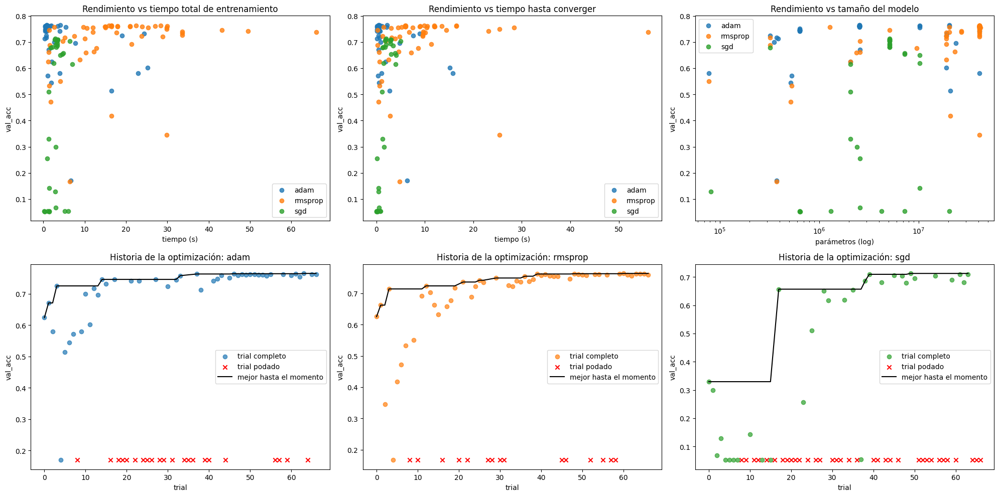

In [33]:
colors = {"adam": "tab:blue", "rmsprop": "tab:orange", "sgd": "tab:green"}

fig, axes = plt.subplots(2, 3, figsize=(20, 10))
for opt_name, g in done.groupby("params_optimizer"):
    axes[0, 0].scatter(g["user_attrs_train_time"], g["value"], label=opt_name, color=colors[opt_name], alpha=0.8)
    axes[0, 1].scatter(g["user_attrs_conv_time"], g["value"], label=opt_name, color=colors[opt_name], alpha=0.8)
    axes[0, 2].scatter(g["user_attrs_n_params"], g["value"], label=opt_name, color=colors[opt_name], alpha=0.8)
axes[0, 0].set(title="Rendimiento vs tiempo total de entrenamiento", xlabel="tiempo (s)", ylabel="val_acc")
axes[0, 1].set(title="Rendimiento vs tiempo hasta converger", xlabel="tiempo (s)", ylabel="val_acc")
axes[0, 2].set_xscale("log")
axes[0, 2].set(title="Rendimiento vs tamaño del modelo", xlabel="parámetros (log)", ylabel="val_acc")
for ax in axes[0]:
    ax.legend()

for ax, opt_name in zip(axes[1], OPTIMIZER_NAMES):
    g_all = df_mlp[df_mlp["params_optimizer"] == opt_name].sort_values("number")
    g_done = g_all[g_all["state"] == "COMPLETE"]
    g_prun = g_all[g_all["state"] == "PRUNED"]
    ax.scatter(g_done["number"], g_done["value"], alpha=0.7, label="trial completo", color=colors[opt_name])
    if len(g_prun):
        ax.scatter(g_prun["number"], [g_done["value"].min()] * len(g_prun), marker="x", color="red",
                   label="trial podado")
    ax.plot(g_done["number"], g_done["value"].cummax(), color="k", label="mejor hasta el momento")
    ax.set(title=f"Historia de la optimización: {opt_name}", xlabel="trial", ylabel="val_acc")
    ax.legend()
plt.tight_layout()
plt.show()

### Curvas por época y acción del pruner

Cada línea es la `val_acc` por época de un trial, separada por optimizador. Los trials podados (rojo) terminan antes; permiten ver en qué época y con qué nivel de accuracy el pruner decidió cortar, y qué configuraciones divergen, se estancan o tienen curvas ruidosas.

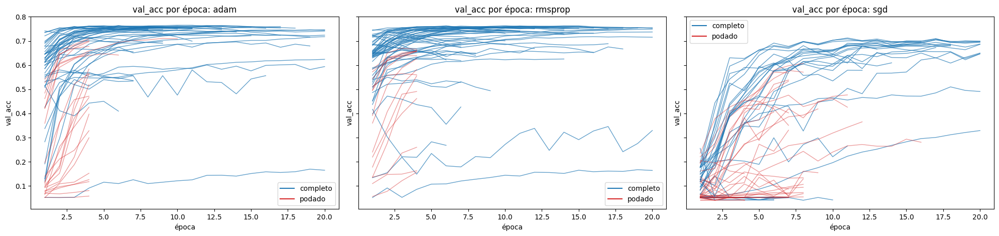

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(20, 4.8), sharey=True)
for ax, (opt_name, study) in zip(axes, studies_mlp.items()):
    for t in study.trials:
        if not t.intermediate_values:
            continue
        steps, vals = zip(*sorted(t.intermediate_values.items()))
        pruned_t = t.state.name == "PRUNED"
        ax.plot([s + 1 for s in steps], vals, color="tab:red" if pruned_t else "tab:blue",
                alpha=0.45 if pruned_t else 0.7, lw=1)
    ax.plot([], [], color="tab:blue", label="completo")
    ax.plot([], [], color="tab:red", label="podado")
    ax.set(title=f"val_acc por época: {opt_name}", xlabel="época", ylabel="val_acc")
    ax.legend()
plt.tight_layout()
plt.show()

### Chequeo de bordes del espacio de búsqueda

Para cada optimizador se toman los 10 mejores trials y se cuenta cuántos tienen cada hiperparámetro dentro del 10 % exterior del rango (en escala logarítmica cuando corresponde) o, en los discretos, en el valor mínimo o máximo permitido. Si muchos mejores trials caen en un borde, no se puede asegurar que ese valor sea un óptimo: el rango habría que ampliarlo.

In [35]:
def border_report(df, opt_name, top_k=10, margin=0.1):
    sub = df[(df["params_optimizer"] == opt_name) & (df["state"] == "COMPLETE")].nlargest(top_k, "value")
    rows = []
    for name, (low, high, log) in FLOAT_BOUNDS.items():
        col = f"params_{name}"
        if col not in sub.columns or sub[col].isna().all():
            continue
        v = sub[col].dropna().to_numpy(dtype=float)
        if log:
            z = (np.log(v) - np.log(low)) / (np.log(high) - np.log(low))
        else:
            z = (v - low) / (high - low)
        rows.append({"hiperparámetro": name, "mín. observado": v.min(), "máx. observado": v.max(),
                     "cerca del límite inferior": int((z <= margin).sum()),
                     "cerca del límite superior": int((z >= 1 - margin).sum()), "de": len(v)})
    discrete = {"batch_size": SPACE["batch_size"], "max_features": SPACE["max_features"],
                "units_l1": SPACE["units"]}
    for name, values in discrete.items():
        col = f"params_{name}"
        v = sub[col].dropna().to_numpy()
        rows.append({"hiperparámetro": name, "mín. observado": v.min(), "máx. observado": v.max(),
                     "cerca del límite inferior": int((v == min(values)).sum()),
                     "cerca del límite superior": int((v == max(values)).sum()), "de": len(v)})
    return pd.DataFrame(rows).set_index("hiperparámetro")


border_tables = {}
for opt_name in OPTIMIZER_NAMES:
    border_tables[opt_name] = border_report(df_mlp, opt_name)
    print(f"--- {opt_name}: 10 mejores trials ---")
    display(border_tables[opt_name].round(5))
pd.concat(border_tables, names=["optimizador"]).to_csv(f"{RESULTS_DIR}/border_check.csv")

--- adam: 10 mejores trials ---


,mín. observado,máx. observado,cerca del límite inferior,cerca del límite superior,de
hiperparámetro,,,,,
weight_decay,0.00000,0.00000,4,0,10
dropout,0.30000,0.70000,0,1,10
lr_adam,0.00153,0.01202,0,0,10
beta1,0.79619,0.99324,0,2,10
beta2,0.95470,0.98550,0,0,10
batch_size,512.00000,512.00000,0,10,10
max_features,20000.00000,20000.00000,0,10,10
units_l1,128.00000,1024.00000,0,0,10


--- rmsprop: 10 mejores trials ---


,mín. observado,máx. observado,cerca del límite inferior,cerca del límite superior,de
hiperparámetro,,,,,
weight_decay,0.00000,0.00000,4,0,10
dropout,0.00000,0.20000,1,0,10
lr_rmsprop,0.00004,0.00023,0,0,10
rms_alpha,0.91035,0.96849,0,0,10
rms_momentum,0.45263,0.77271,0,0,10
batch_size,128.00000,256.00000,0,0,10
max_features,20000.00000,20000.00000,0,10,10
units_l1,2048.00000,2048.00000,0,10,10


--- sgd: 10 mejores trials ---


,mín. observado,máx. observado,cerca del límite inferior,cerca del límite superior,de
hiperparámetro,,,,,
weight_decay,0.00000,0.00042,0,0,10
dropout,0.50000,0.70000,0,5,10
lr_sgd,0.19041,1.17702,0,0,10
sgd_momentum,0.36906,0.80148,0,0,10
batch_size,128.00000,128.00000,0,0,10
max_features,5000.00000,5000.00000,0,0,10
units_l1,1024.00000,1024.00000,0,0,10


### Importancia de hiperparámetros (fANOVA)

La importancia se calcula **por optimizador**, de modo que cada estudio contiene los mismos hiperparámetros en todos sus trials (por ejemplo, `beta1` y `beta2` solo se evalúan dentro del estudio de Adam). Un valor alto indica que, según el modelo de bosque aleatorio de fANOVA, la variación de ese hiperparámetro explica una parte grande de la variación en la `val_acc`. Optuna solo evalúa los parámetros presentes en todos los trials del estudio, por lo que `units_l2` y `units_l3` (condicionales a `n_layers`) pueden quedar fuera y deben interpretarse con las tablas de arriba. La importancia es una medida correlacional sobre los trials muestreados, no un efecto causal.

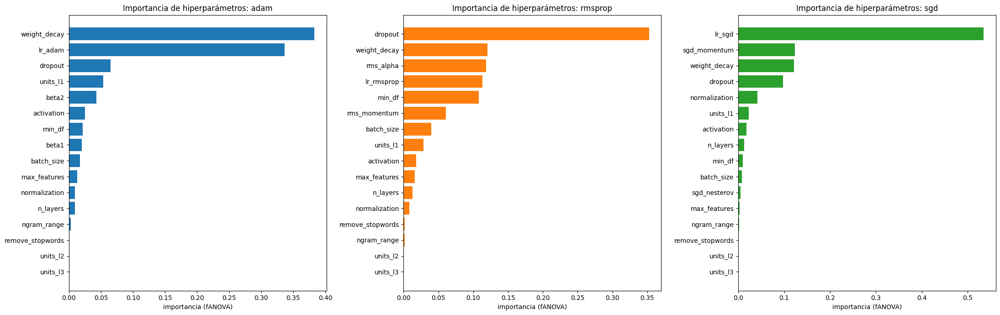

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(22, 7))
importances = {}
for ax, (opt_name, study) in zip(axes, studies_mlp.items()):
    try:
        imp = pd.Series(optuna.importance.get_param_importances(study)).sort_values()
        importances[opt_name] = imp
        ax.barh(imp.index, imp.values, color=colors[opt_name])
        ax.set(title=f"Importancia de hiperparámetros: {opt_name}", xlabel="importancia (fANOVA)")
    except Exception as e:
        ax.set_title(f"{opt_name}: no se pudo calcular")
        print(f"No se pudo calcular la importancia para {opt_name}:", e)
plt.tight_layout()
plt.show()
if importances:
    pd.DataFrame(importances).to_csv(f"{RESULTS_DIR}/param_importance.csv")

## 12. Efecto de cada hiperparámetro: un factor por vez

La búsqueda varía todos los hiperparámetros a la vez, lo que mezcla sus efectos. Para aislarlos se toma la **mejor configuración** y se cambia **un solo hiperparámetro por vez**, entrenando un número fijo de épocas (`ABL_EPOCHS`), sin early stopping y sin pruning, sobre la misma partición train/validación. Cada variante se repite con 3 semillas (`ABL_SEEDS`); las curvas muestran la media y una banda de ±1 desvío estándar, y las tablas la media ± desvío.

Se estudian:
1. **Learning rate**: de dos órdenes de magnitud menos a dos más que el óptimo, para observar entrenamiento lento (plateau), óptimo, ruido y divergencia.
2. **Batch size**.
3. **Vectorización**: tamaño del vocabulario (`max_features`) y n-gramas.
4. **Optimizador**: cada uno con sus mejores hiperparámetros según su propio estudio.

Los gráficos muestran, de izquierda a derecha, `val_acc`, `val_loss` (escala log), `train_loss` (escala log) y tiempo hasta converger. Las tablas incluyen época y tiempo de convergencia, tiempo por época, *gap* final entre entrenamiento y validación y si hubo divergencia (valores no finitos en el loss de entrenamiento).

In [37]:
ABL_EPOCHS = 30
ABL_SEEDS = [42, 123, 2024]


def ms(values, d=4):
    return f"{np.mean(values):.{d}f} ± {np.std(values):.{d}f}"


def run_curve(p, seed, epochs, tag):
    set_seed(seed)
    X_tr, X_val = get_search_features(p["remove_stopwords"], p["normalization"], ngram_tuple(p["ngram_range"]),
                                      p["max_features"], p["min_df"])
    train_loader, val_loader = make_loaders(X_tr, y_search_tr, X_val, y_search_val, p["batch_size"])
    model = build_model(p, X_tr.shape[1], True)
    optimizer = build_optimizer(model, p)
    safe_tag = re.sub(r"[^A-Za-z0-9_.=-]", "_", tag)
    writer = SummaryWriter(log_dir=f"runs/ablation/{safe_tag}_seed{seed}")
    with mlflow.start_run(run_name=f"ablation_{safe_tag}_seed{seed}"):
        mlflow.log_params({**p, "seed": seed, "n_params": count_params(model)})
        h = train_model(model, train_loader, val_loader, optimizer, epochs, writer=writer,
                        run_name=safe_tag, patience=None, verbose=False)
        mlflow.log_metrics({"best_val_acc": h["best_val_acc"], "conv_epoch": h["conv_epoch"],
                            "conv_time_s": h["conv_time"], "train_time_s": h["train_time"]})
    writer.close()
    del train_loader, val_loader, model, optimizer
    free_memory()
    return h


def ablation(name, variants, epochs=ABL_EPOCHS, seeds=ABL_SEEDS):
    curves = {}
    for label, p in variants.items():
        curves[label] = [run_curve(p, s, epochs, f"{name}_{label}") for s in seeds]
        print(f"  {name} | {label}: listo")
    return curves


def ablation_table(curves):
    rows = []
    for label, hs in curves.items():
        rows.append({
            "variante": label,
            "mejor val_acc": ms([h["best_val_acc"] for h in hs]),
            "época de convergencia": ms([h["conv_epoch"] for h in hs], 1),
            "tiempo hasta converger (s)": ms([h["conv_time"] for h in hs], 2),
            "s/época": ms([np.mean(h["epoch_time"]) for h in hs], 3),
            "gap train-val final": ms([h["final_train_acc"] - h["final_val_acc"] for h in hs]),
            "diverge": any(not np.isfinite(h["train_loss"]).all() for h in hs),
        })
    return pd.DataFrame(rows).set_index("variante")


def plot_ablation(curves, title):
    fig, axes = plt.subplots(1, 4, figsize=(24, 4.8))
    for label, hs in curves.items():
        for ax, key in zip(axes[:3], ["val_acc", "val_loss", "train_loss"]):
            arr = np.array([h[key] for h in hs], dtype=float)
            m, s = arr.mean(axis=0), arr.std(axis=0)
            x = np.arange(1, arr.shape[1] + 1)
            ax.plot(x, m, label=label)
            ax.fill_between(x, m - s, m + s, alpha=0.2)
    axes[0].set(title="val_acc", xlabel="época", ylabel="accuracy")
    axes[1].set(title="val_loss", xlabel="época", ylabel="cross-entropy", yscale="log")
    axes[2].set(title="train_loss", xlabel="época", ylabel="cross-entropy", yscale="log")
    axes[0].legend(fontsize=8)
    labels = list(curves.keys())
    means = [np.mean([h["conv_time"] for h in curves[l]]) for l in labels]
    stds = [np.std([h["conv_time"] for h in curves[l]]) for l in labels]
    axes[3].bar(range(len(labels)), means, yerr=stds, capsize=3)
    axes[3].set_xticks(range(len(labels)), labels, rotation=60, ha="right", fontsize=8)
    axes[3].set(title="Tiempo hasta converger", ylabel="segundos")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


mlflow.end_run()
base = dict(params_mlp)
base_opt = base["optimizer"]
lr_key = f"lr_{base_opt}"
print("Configuración base:", base)

Configuración base: {'remove_stopwords': True, 'normalization': 'lemmatize', 'ngram_range': '1gram', 'max_features': 20000, 'min_df': 1, 'batch_size': 512, 'n_layers': 1, 'units_l1': 128, 'activation': 'relu', 'dropout': 0.7, 'weight_decay': 9.77571321993535e-08, 'lr_adam': 0.004353156454371769, 'beta1': 0.9120473844865505, 'beta2': 0.9615543556125106, 'optimizer': 'adam'}


### 12.1 Learning rate

Se multiplica el `lr` óptimo por 0.01, 0.1, 1, 10 y 100 manteniendo todo lo demás fijo.

  lr | lr x0.01 (4.4e-05): listo
  lr | lr x0.1 (4.4e-04): listo
  lr | lr x1 (4.4e-03): listo
  lr | lr x10 (4.4e-02): listo
  lr | lr x100 (4.4e-01): listo


,mejor val_acc,época de convergencia,tiempo hasta converger (s),s/época,gap train-val final,diverge
variante,,,,,,
lr x0.01 (4.4e-05),0.4148 ± 0.0466,30.0 ± 0.0,1.57 ± 0.07,0.052 ± 0.002,-0.0142 ± 0.0156,False
lr x0.1 (4.4e-04),0.7424 ± 0.0006,28.0 ± 0.8,1.44 ± 0.02,0.052 ± 0.001,0.0329 ± 0.0020,False
lr x1 (4.4e-03),0.7627 ± 0.0016,8.0 ± 0.0,0.41 ± 0.01,0.052 ± 0.001,0.2236 ± 0.0011,False
lr x10 (4.4e-02),0.7474 ± 0.0038,3.3 ± 1.2,0.17 ± 0.06,0.052 ± 0.001,0.2052 ± 0.0038,False
lr x100 (4.4e-01),0.3101 ± 0.0080,29.7 ± 0.5,1.55 ± 0.05,0.052 ± 0.001,-0.1160 ± 0.0123,False


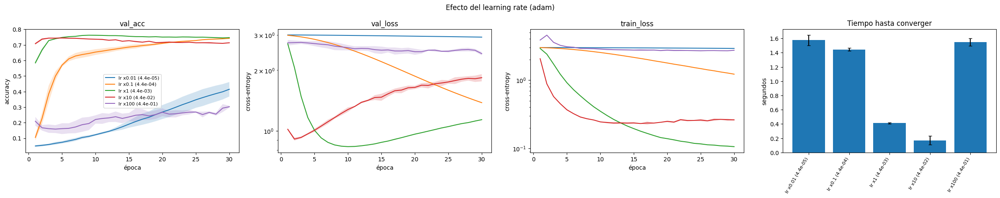

In [38]:
lr_variants = {f"lr x{m:g} ({base[lr_key] * m:.1e})": {**base, lr_key: base[lr_key] * m}
               for m in [0.01, 0.1, 1, 10, 100]}
curves_lr = ablation("lr", lr_variants)
df_abl_lr = ablation_table(curves_lr)
df_abl_lr.to_csv(f"{RESULTS_DIR}/ablation_lr.csv")
display(df_abl_lr)
plot_ablation(curves_lr, f"Efecto del learning rate ({base_opt})")

### 12.2 Batch size

Se varía `batch_size` entre 32 y 512. A igual número de épocas, un batch chico hace más actualizaciones por época (más ruido, más pasos), y uno grande hace menos pasos pero más baratos en GPU; el tiempo por época y el de convergencia permiten ver el balance.

  batch_size | bs=32: listo
  batch_size | bs=64: listo
  batch_size | bs=128: listo
  batch_size | bs=256: listo
  batch_size | bs=512: listo


,mejor val_acc,época de convergencia,tiempo hasta converger (s),s/época,gap train-val final,diverge
variante,,,,,,
bs=32,0.7424 ± 0.0022,3.0 ± 0.0,2.05 ± 0.08,0.683 ± 0.008,0.2232 ± 0.0031,False
bs=64,0.7474 ± 0.0004,3.3 ± 0.5,1.14 ± 0.18,0.349 ± 0.003,0.2425 ± 0.0004,False
bs=128,0.7561 ± 0.0010,4.3 ± 0.5,0.76 ± 0.09,0.175 ± 0.003,0.2473 ± 0.0023,False
bs=256,0.7621 ± 0.0006,7.0 ± 0.8,0.64 ± 0.08,0.091 ± 0.002,0.2328 ± 0.0014,False
bs=512,0.7627 ± 0.0016,8.0 ± 0.0,0.42 ± 0.01,0.052 ± 0.001,0.2236 ± 0.0011,False


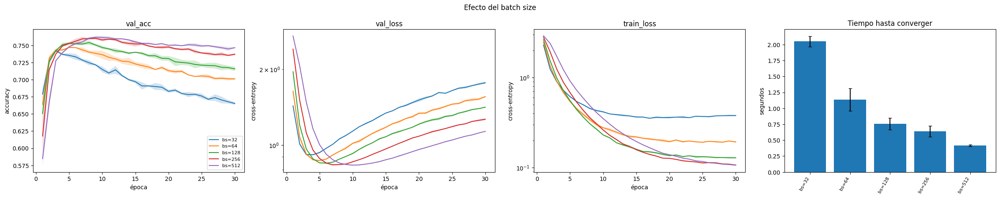

In [39]:
bs_variants = {f"bs={b}": {**base, "batch_size": b} for b in SPACE["batch_size"]}
curves_bs = ablation("batch_size", bs_variants)
df_abl_bs = ablation_table(curves_bs)
df_abl_bs.to_csv(f"{RESULTS_DIR}/ablation_batch_size.csv")
display(df_abl_bs)
plot_ablation(curves_bs, "Efecto del batch size")

### 12.3 Vectorización

Se varía por separado el tamaño del vocabulario (`max_features`) y el uso de bigramas (`ngram_range`), con el resto fijo. Un vocabulario mayor aumenta la dimensión de entrada y el número de parámetros de la primera capa (y por lo tanto el costo por época).

  max_features | max_features=2000: listo
  max_features | max_features=5000: listo
  max_features | max_features=10000: listo
  max_features | max_features=20000: listo


,mejor val_acc,época de convergencia,tiempo hasta converger (s),s/época,gap train-val final,diverge
variante,,,,,,
max_features=2000,0.6565 ± 0.0002,7.3 ± 0.5,0.24 ± 0.01,0.033 ± 0.000,0.2470 ± 0.0031,False
max_features=5000,0.7187 ± 0.0015,7.3 ± 0.5,0.26 ± 0.02,0.034 ± 0.000,0.2564 ± 0.0010,False
max_features=10000,0.7461 ± 0.0012,8.0 ± 2.2,0.33 ± 0.09,0.039 ± 0.002,0.2370 ± 0.0015,False
max_features=20000,0.7627 ± 0.0016,8.0 ± 0.0,0.45 ± 0.06,0.053 ± 0.003,0.2236 ± 0.0011,False


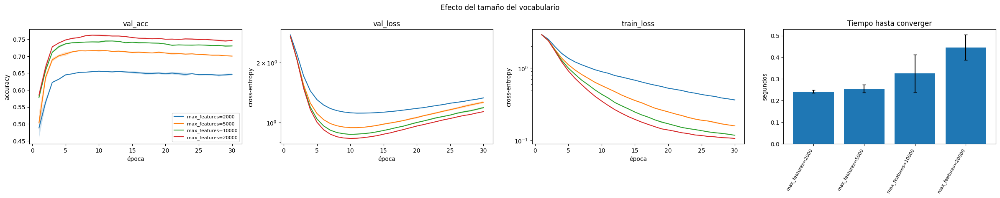

  ngram_range | ngram_range=1gram: listo
  ngram_range | ngram_range=1_2gram: listo


,mejor val_acc,época de convergencia,tiempo hasta converger (s),s/época,gap train-val final,diverge
variante,,,,,,
ngram_range=1gram,0.7627 ± 0.0016,8.0 ± 0.0,0.45 ± 0.06,0.053 ± 0.002,0.2236 ± 0.0011,False
ngram_range=1_2gram,0.7484 ± 0.0012,7.0 ± 0.0,0.39 ± 0.05,0.053 ± 0.001,0.2370 ± 0.0035,False


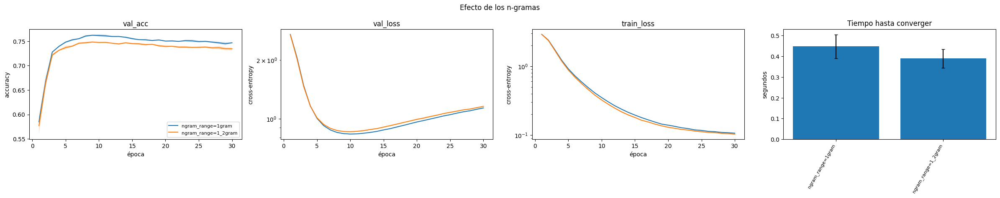

In [40]:
mf_variants = {f"max_features={m}": {**base, "max_features": m} for m in SPACE["max_features"]}
curves_mf = ablation("max_features", mf_variants)
df_abl_mf = ablation_table(curves_mf)
df_abl_mf.to_csv(f"{RESULTS_DIR}/ablation_max_features.csv")
display(df_abl_mf)
plot_ablation(curves_mf, "Efecto del tamaño del vocabulario")

ng_variants = {f"ngram_range={n}": {**base, "ngram_range": n} for n in ["1gram", "1_2gram"]}
curves_ng = ablation("ngram_range", ng_variants)
df_abl_ng = ablation_table(curves_ng)
df_abl_ng.to_csv(f"{RESULTS_DIR}/ablation_ngram_range.csv")
display(df_abl_ng)
plot_ablation(curves_ng, "Efecto de los n-gramas")

### 12.4 Optimizador

Se compara el mejor trial de cada estudio (Adam, RMSprop, SGD), cada uno con su propio `lr`, sus momentos y su `weight_decay`. Las demás decisiones (arquitectura, vectorización, `batch_size`) son las del mejor trial de cada optimizador, por lo que esta comparación incluye también las diferencias que Optuna encontró como mejores para cada uno.

  optimizer | adam (lr=4.4e-03): listo
  optimizer | rmsprop (lr=8.5e-05): listo
  optimizer | sgd (lr=3.2e-01): listo


,mejor val_acc,época de convergencia,tiempo hasta converger (s),s/época,gap train-val final,diverge
variante,,,,,,
adam (lr=4.4e-03),0.7627 ± 0.0016,8.0 ± 0.0,0.45 ± 0.03,0.053 ± 0.002,0.2236 ± 0.0011,False
rmsprop (lr=8.5e-05),0.7611 ± 0.0015,7.7 ± 0.5,11.44 ± 0.70,1.498 ± 0.012,0.2464 ± 0.0009,False
sgd (lr=3.2e-01),0.7072 ± 0.0045,10.7 ± 1.2,1.79 ± 0.18,0.169 ± 0.003,0.2712 ± 0.0023,False


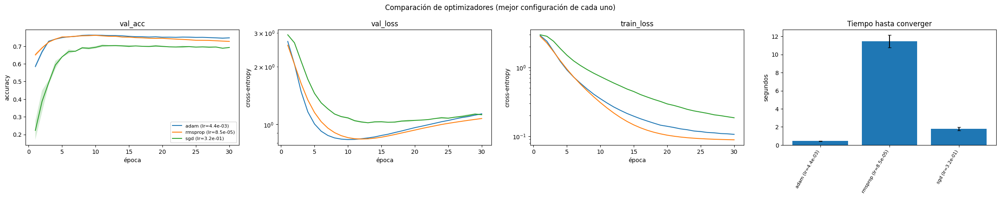

In [41]:
opt_variants = {f"{k} (lr={v[f'lr_{k}']:.1e})": v for k, v in best_by_optimizer(studies_mlp).items()}
curves_opt = ablation("optimizer", opt_variants)
df_abl_opt = ablation_table(curves_opt)
df_abl_opt.to_csv(f"{RESULTS_DIR}/ablation_optimizer.csv")
display(df_abl_opt)
plot_ablation(curves_opt, "Comparación de optimizadores (mejor configuración de cada uno)")

## 13. Comparación multi-semilla y robustez de la búsqueda

### 13.1 Softmax vs MLP con varias semillas

Un único entrenamiento puede favorecer a un modelo por azar en la inicialización o en el orden de los batches. En esta sección, se repite el **entrenamiento final** de ambos modelos con las semillas de `SEEDS`, con los hiperparámetros ya elegidos, en el mismo hardware y con el mismo protocolo (misma partición, mismas épocas, mismo test). La semilla afecta la inicialización de los pesos, el dropout y el orden de los batches; la partición de datos y el vocabulario son fijos.

Se reporta media ± desvío por modelo, la diferencia pareada por semilla con su error estándar y un test t pareado. Una mejora menor a unas 2 veces su error estándar no se considera evidencia de diferencia real.

In [42]:
mlflow.end_run()
final_results = {("MLP", SEED): res_mlp, ("Softmax", SEED): res_softmax}
for seed in SEEDS:
    if ("MLP", seed) in final_results:
        continue
    final_results[("MLP", seed)] = run_final(params_mlp, True, f"mlp_s{seed}", EPOCHS_FINAL_MLP,
                                             seed=seed, verbose=False)
    final_results[("Softmax", seed)] = run_final(params_softmax, False, f"softmax_s{seed}",
                                                 EPOCHS_FINAL_SOFTMAX, seed=seed, verbose=False)
    print(f"semilla {seed}: listo")

rows = []
for (name, seed), r in final_results.items():
    h = r["history"]
    rows.append({"modelo": name, "semilla": seed,
                 "test_acc": accuracy_score(r["labels"], r["preds"]),
                 "test_macro_F1": f1_score(r["labels"], r["preds"], average="macro"),
                 "train_acc final": h["final_train_acc"],
                 "tiempo entrenamiento (s)": h["train_time"],
                 "s/época": float(np.mean(h["epoch_time"]))})
df_seeds = pd.DataFrame(rows).sort_values(["modelo", "semilla"]).reset_index(drop=True)
df_seeds.to_csv(f"{RESULTS_DIR}/final_by_seed.csv", index=False)
display(df_seeds.round(4))

metrics = ["test_acc", "test_macro_F1", "train_acc final", "tiempo entrenamiento (s)", "s/época"]
agg = df_seeds.groupby("modelo")[metrics].agg(["mean", "std"]).round(4)
agg.to_csv(f"{RESULTS_DIR}/final_mean_std.csv")
display(agg)

pivot = df_seeds.pivot(index="semilla", columns="modelo", values="test_acc")
diff = pivot["MLP"] - pivot["Softmax"]
se = diff.std(ddof=1) / np.sqrt(len(diff))
t_stat, p_value = stats.ttest_rel(pivot["MLP"], pivot["Softmax"])
print(f"\nDiferencia de test_acc (MLP − Softmax) sobre {len(diff)} semillas: "
      f"{diff.mean():.4f} ± {se:.4f} (error estándar)")
print(f"Test t pareado: t={t_stat:.3f}, p={p_value:.4g}")
print("La diferencia media supera 2 errores estándar:", abs(diff.mean()) > 2 * se)

semilla 123: listo
semilla 2024: listo
semilla 7: listo
semilla 99: listo


,modelo,semilla,test_acc,test_macro_F1,train_acc final,tiempo entrenamiento (s),s/época
0,MLP,7,0.7049,0.6955,0.9224,0.8333,0.0833
1,MLP,42,0.7023,0.6929,0.9196,0.8338,0.0834
2,MLP,99,0.7043,0.6958,0.9186,0.8272,0.0827
3,MLP,123,0.7034,0.6942,0.9212,0.8130,0.0813
4,MLP,2024,0.7017,0.6931,0.9202,0.8488,0.0849
5,Softmax,7,0.6840,0.6736,0.9623,3.1874,0.2898
6,Softmax,42,0.6841,0.6743,0.9623,2.8900,0.2627
7,Softmax,99,0.6837,0.6736,0.9620,2.8916,0.2629
8,Softmax,123,0.6830,0.6727,0.9619,2.9485,0.2680
9,Softmax,2024,0.6839,0.6735,0.9625,4.0842,0.3713


test_acc         test_macro_F1         train_acc final          \
            mean     std          mean     std            mean     std   
modelo                                                                   
MLP       0.7033  0.0013        0.6943  0.0013          0.9204  0.0015   
Softmax   0.6837  0.0005        0.6735  0.0005          0.9622  0.0003   

        tiempo entrenamiento (s)         s/época          
                            mean     std    mean     std  
modelo                                                    
MLP                       0.8312  0.0129  0.0831  0.0013  
Softmax                   3.2003  0.5090  0.2909  0.0463


Diferencia de test_acc (MLP − Softmax) sobre 5 semillas: 0.0196 ± 0.0007 (error estándar)
Test t pareado: t=30.050, p=7.304e-06
La diferencia media supera 2 errores estándar: True


### 13.2 Robustez de la búsqueda frente a la semilla del sampler

Se repite la búsqueda del MLP con otras dos semillas del sampler (`SEARCH_SEEDS_EXTRA`), con un presupuesto menor por optimizador (`N_TRIALS_REPEAT`), para ver si el mejor resultado y los hiperparámetros elegidos dependen de la semilla. Para comparar con presupuesto equivalente, de la búsqueda principal se considera también el mejor resultado de sus primeros `N_TRIALS_REPEAT` trials por optimizador. Esta celda es la más costosa de la sección; si la sesión se interrumpe, los estudios se reanudan desde `results/`.

In [25]:
SEARCH_SEEDS_EXTRA = [123, 2024]
N_TRIALS_REPEAT = 30

repeat_studies = {SEED: studies_mlp}
for s in SEARCH_SEEDS_EXTRA:
    repeat_studies[s] = run_search(use_hidden=True, tag=f"mlp_search_s{s}", n_trials=N_TRIALS_REPEAT, seed=s)


def best_first_n(studies, n):
    vals = []
    for study in studies.values():
        vals += [t.value for t in study.trials if t.state.name == "COMPLETE" and t.number < n]
    return max(vals)


rows = []
for s, studies in repeat_studies.items():
    p, t = best_of(studies)
    rows.append({
        "semilla del sampler": s,
        "trials por optimizador": len(studies["adam"].trials),
        "mejor val_acc": t.value,
        f"mejor val_acc (primeros {N_TRIALS_REPEAT} trials)": best_first_n(studies, N_TRIALS_REPEAT),
        "optimizador": p["optimizer"],
        "capas": p["n_layers"],
        "unidades": hidden_units_from(p),
        "activación": p["activation"],
        "dropout": p["dropout"],
        "batch_size": p["batch_size"],
        "max_features": p["max_features"],
        "ngram_range": p["ngram_range"],
        "val_acc por optimizador": {k: round(v.best_value, 4) for k, v in studies.items()},
    })
df_repeat = pd.DataFrame(rows).set_index("semilla del sampler")
df_repeat.to_csv(f"{RESULTS_DIR}/search_seed_robustness.csv")
df_repeat

,trials por optimizador,mejor val_acc,mejor val_acc (primeros 30 trials),optimizador,capas,unidades,activación,dropout,batch_size,max_features,ngram_range,val_acc por optimizador
semilla del sampler,,,,,,,,,,,,
42,67,0.764914,0.748564,adam,1,"(128,)",relu,0.7,512,20000,1gram,"{'adam': 0.7649, 'rmsprop': 0.7631, 'sgd': 0.7..."
123,30,0.728679,0.728679,adam,2,"(2048, 128)",selu,0.1,512,20000,1_2gram,"{'adam': 0.7287, 'rmsprop': 0.726, 'sgd': 0.7269}"
2024,30,0.763146,0.763146,rmsprop,1,"(128,)",tanh,0.1,128,20000,1gram,"{'adam': 0.7521, 'rmsprop': 0.7631, 'sgd': 0.696}"


## 14. Conclusiones

Todos los tiempos se midieron con `time.perf_counter()` en una GPU NVIDIA T4. La partición de validación de la búsqueda tiene 2.263 documentos, por lo que una accuracy cercana a 0.76 tiene un error de muestreo de aproximadamente ±0.9 puntos porcentuales; las diferencias menores entre trials individuales no son interpretables. Las diferencias entre semillas se comparan contra el desvío observado en las secciones 12 y 13.

### 14.1 Resultado general: softmax vs MLP (secciones 8–10 y 13.1)

| | Softmax | MLP |
|---|---|---|
| Accuracy en test (5 semillas) | 0.6837 ± 0.0005 | **0.7033 ± 0.0013** |
| Macro-F1 en test (5 semillas) | 0.6735 ± 0.0005 | **0.6943 ± 0.0013** |
| Accuracy de train al final | 0.9622 ± 0.0003 | 0.9204 ± 0.0015 |
| Mejor `val_acc` de la búsqueda | 0.7556 | 0.7649 |
| Parámetros | 400.020 | 2.562.708 |
| Tiempo por época (s) | 0.291 ± 0.046 | 0.083 ± 0.001 |
| Tiempo de entrenamiento final (s) | 3.20 ± 0.51 | 0.83 ± 0.01 |
| Época / tiempo hasta converger del mejor trial | 6 / 1.17 s | 8 / 0.44 s |
| Tiempo de búsqueda (s) | 946 | 1.897 |
| Trials completos / podados | 145 / 56 | 129 / 72 |

(± es el desvío estándar muestral entre las 5 semillas.)

- **Diferencia.** El MLP supera al softmax en 0.0196 de accuracy (error estándar 0.0007 de la diferencia pareada por semilla; t pareado = 30.05, p = 7.3·10⁻⁶), unas 28 veces su error estándar. Las 5 semillas favorecen al MLP: la peor accuracy del MLP (0.7017) es mayor que la mejor del softmax (0.6841). La mejora es consistente pero de unos 2 puntos.
- **Alcance de la prueba.** Las semillas varían la inicialización y el orden de los batches, pero no la partición ni el conjunto de test, por lo que el p-valor no incorpora el error de muestreo del test (el error estándar binomial de cada accuracy ronda 0.5 puntos). Un bootstrap sobre las predicciones lo cubriría y no se realizó.
- **Validación vs test.** Ambos modelos rinden menos en test que en la validación de la búsqueda (MLP: 0.7649 → 0.7023; softmax: 0.7556 → 0.6841). Es consistente con el sesgo optimista de elegir el mejor de 201 trials y con que la validación sea una partición aleatoria del train mientras que el test oficial de 20 Newsgroups es posterior en el tiempo. Ambos efectos no se separaron.
- **Costo.** El tiempo por época del MLP resulta menor a pesar de tener 6.4 veces más parámetros, pero esa comparación refleja el `batch_size` elegido por cada búsqueda (512 para el MLP, 64 para el softmax), no el costo del modelo: en la sección 12.2 el mismo MLP con `batch_size=64` tarda 0.349 s/época, del mismo orden que el softmax. La búsqueda del MLP demoró el doble que la del softmax.
- **Sobreajuste.** El softmax sobreajusta más (gap train–test de 0.279 contra 0.217 del MLP). El mejor MLP es una red de una capa de 128 unidades con `dropout=0.7` y `weight_decay` ≈ 0 (≤ 4.3·10⁻⁷ en los 10 mejores trials de Adam), es decir, una arquitectura chica y muy regularizada.
- **Por clase (MLP, `classification_report`).** Los mejores F1 son rec.sport.hockey (0.89), rec.sport.baseball (0.86) y talk.politics.mideast (0.82). Los peores son talk.religion.misc (0.32, recall 0.27, con solo 251 ejemplos de test), talk.politics.misc (0.52) y alt.atheism (0.53), clases de temática afín entre sí. rec.autos tiene precisión 0.48 y recall 0.81: el modelo la predice con demasiada frecuencia.

### 14.2 Búsqueda y pruning (sección 11)

| Optimizador | Completos / podados | Tiempo real de podados (s) | Tiempo estimado sin poda (s) | Ahorro |
|---|---|---|---|---|
| adam | 45 / 22 | 9.2 | 29.0 | 19.7 s (68.1 %) |
| rmsprop | 52 / 15 | 58.4 | 182.0 | 123.6 s (67.9 %) |
| sgd | 32 / 35 | 52.0 | 95.2 | 43.3 s (45.4 %) |
| **MLP total** | 129 / 72 | 119.6 | 306.2 | **186.6 s (60.9 %)** |
| Softmax total | 145 / 56 | 44.0 | 138.8 | 94.8 s (68.3 %) |

- El pruner cortó el 36 % de los trials del MLP y el 28 % de los del softmax. El tiempo sin poda es una estimación (tiempo por época del trial podado por las épocas medias de un trial completo). En términos absolutos el ahorro es pequeño (≈187 s sobre 1.897 s de búsqueda, cerca del 10 %) porque cada trial dura pocos segundos en la T4; el pruning sería más valioso con trials más largos.
- **Reparto del tiempo.** RMSprop consumió el 63 % del tiempo total de la búsqueda (ver tabla de tiempo por optimizador de la sección 11) porque 44 de sus 67 trials usaron 2048 unidades en la primera capa (≈41 millones de parámetros) y no superó a Adam.
- **Mejor resultado por optimizador:** Adam 0.7649, RMSprop 0.7631, SGD 0.7123. SGD es el más sensible al `lr` (importancia fANOVA 0.53): solo el cuartil de `lr` entre 0.093 y 0.349 produce una media razonable (0.616); los demás cuartiles quedan entre 0.11 y 0.46 (tabla de `lr` por cuartil). Tuvo además la mayor proporción de trials podados (35 de 67).
- **Top 10.** Sus `val_acc` van de 0.7623 a 0.7649, un rango (0.26 puntos) menor que el error de muestreo de la validación y comparable al desvío entre semillas (0.0016, sección 12): no hay evidencia para ordenar esos diez trials. Los diez son de una capa, unigramas, `max_features=20000` y `weight_decay` ≈ 0; 6 son de Adam y 4 de RMSprop, y ninguno de SGD.
- **Avance de la búsqueda.** El mejor trial de Adam apareció en el número 63 de 67 y el de RMSprop en el 60 de 67 (tabla de mejor `val_acc` acumulada). La búsqueda seguía mejorando cerca del final, por lo que 67 trials por optimizador es un presupuesto ajustado.
- **Concentración del muestreo.** 160 de 201 trials usaron una capa oculta, 52 de 67 de Adam usaron `batch_size=512` y 54 de 67 de Adam y RMSprop usaron `max_features=20000` (tabla de concentración). TPE se concentró en una región pequeña del espacio, de modo que los promedios por grupo de la sección 11 comparan muestras muy desiguales y confundidas entre sí.
- **Bordes del espacio (`border_check`).** Los diez mejores trials de Adam están todos en el límite superior de `batch_size` (512) y de `max_features` (20000); los de RMSprop, en el límite superior de `max_features` y de `units_l1` (2048); en SGD, la mitad está en el límite superior de `dropout` (0.7). En `weight_decay`, 4 de los 10 mejores de Adam y de RMSprop están cerca del límite inferior. Para esos hiperparámetros no puede afirmarse que el valor elegido sea un óptimo. `lr`, `beta1`, `beta2`, `rms_alpha`, `rms_momentum` y `sgd_momentum` tienen su mejor zona en el interior del rango.
- **Importancia (fANOVA, por optimizador).** En Adam, `weight_decay` (0.38) y `lr_adam` (0.34) concentran la mayor parte; en RMSprop, `dropout` (0.35), seguido de `weight_decay`, `rms_alpha` y `lr_rmsprop` (≈0.11–0.12 cada uno); en SGD, `lr_sgd` (0.53), seguido de `sgd_momentum`, `weight_decay` y `dropout` (≈0.10–0.12). La activación (0.02), `ngram_range` y `remove_stopwords` (≈0) tienen importancia baja. La importancia es correlacional y depende de la región muestreada; `units_l2` y `units_l3` figuran con importancia 0 pero solo existen en los 41 trials de 2 y 3 capas, por lo que ese valor no es interpretable.

### 14.3 Efecto de cada hiperparámetro (secciones 11 y 12)

Los experimentos de la sección 12 varían un factor por vez desde la mejor configuración (Adam, una capa de 128 unidades ReLU, `dropout=0.7`, `batch_size=512`, `lr=4.4·10⁻³`, 20.000 características), con 3 semillas y 30 épocas. Los demás factores no se vuelven a sintonizar, por lo que los efectos pueden depender de esa configuración.

**Learning rate (12.1).** El `lr` no modifica el costo por época (0.052 s en todas las variantes); las diferencias de tiempo vienen de las épocas necesarias.

| `lr` | `val_acc` | Época de convergencia | Tiempo hasta converger |
|---|---|---|---|
| ×0.01 (4.4·10⁻⁵) | 0.4148 ± 0.0466 | 30.0 (tope) | 1.57 s |
| ×0.1 (4.4·10⁻⁴) | 0.7424 ± 0.0006 | 28.0 ± 0.8 | 1.44 s |
| ×1 (4.4·10⁻³) | **0.7627 ± 0.0016** | 8.0 ± 0.0 | 0.41 s |
| ×10 (4.4·10⁻²) | 0.7474 ± 0.0038 | 3.3 ± 1.2 | 0.17 s |
| ×100 (4.4·10⁻¹) | 0.3101 ± 0.0080 | 29.7 ± 0.5 | 1.55 s |

Con `lr` bajo el entrenamiento es lento (×0.01 se queda en un plateau de aprendizaje y ×0.1 recién converge hacia la época 28; en ambos casos la época de convergencia está limitada por las 30 épocas del experimento). Con `lr` alto converge rápido pero con peor resultado y mayor variabilidad entre semillas (×10: desvío 0.0038, el más alto de las variantes que entrenan), y con ×100 el entrenamiento colapsa (0.31) aunque la pérdida se mantiene finita, por lo que la columna `diverge` no lo detecta. La tabla de cuartiles de `lr` de la sección 11 es consistente: en Adam, el cuartil de 0.0025 a 0.006 tiene la mayor media (0.7514) y los demás cuartiles son peores.

**Batch size (12.2).** A `lr` fijo:

| `batch_size` | `val_acc` | Épocas hasta converger | Tiempo hasta converger | s/época |
|---|---|---|---|---|
| 32 | 0.7424 ± 0.0022 | 3.0 | 2.05 s | 0.683 |
| 64 | 0.7474 ± 0.0004 | 3.3 | 1.14 s | 0.349 |
| 128 | 0.7561 ± 0.0010 | 4.3 | 0.76 s | 0.175 |
| 256 | 0.7621 ± 0.0006 | 7.0 | 0.64 s | 0.091 |
| 512 | 0.7627 ± 0.0016 | 8.0 | 0.42 s | 0.052 |

Los lotes mayores necesitan más épocas pero cada una cuesta mucho menos en GPU (13 veces menos entre 32 y 512), de modo que el tiempo hasta converger baja de 2.05 s a 0.42 s. La `val_acc` mejora hasta 256 y entre 256 y 512 la diferencia (0.0006) está dentro del desvío entre semillas. Como no se sintonizó el `lr` para cada tamaño, parte del efecto puede deberse a esa interacción.

**Vectorización (12.3).** La `val_acc` aumenta con el vocabulario: 0.6565 (2.000), 0.7187 (5.000), 0.7461 (10.000) y 0.7627 (20.000), con ganancias decrecientes (6.2, 2.7 y 1.7 puntos) y un costo por época que crece de 0.033 a 0.053 s. Como 20.000 es el límite superior probado, no se sabe si más vocabulario seguiría mejorando. Los bigramas con el vocabulario fijo en 20.000 rinden menos que los unigramas (0.7484 ± 0.0012 contra 0.7627 ± 0.0016); con tamaño de vocabulario fijo los bigramas desplazan términos individuales, por lo que no se aísla el efecto de los bigramas por sí mismos.

**Optimizador (12.4).** Cada optimizador usa la mejor configuración completa de su estudio, de modo que la comparación incluye diferencias de arquitectura y de `batch_size`.

| Optimizador | `val_acc` | Épocas hasta converger | Tiempo hasta converger | s/época |
|---|---|---|---|---|
| adam | 0.7627 ± 0.0016 | 8.0 | 0.45 s | 0.053 |
| rmsprop | 0.7611 ± 0.0015 | 7.7 | 11.44 s | 1.498 |
| sgd | 0.7072 ± 0.0045 | 10.7 | 1.79 s | 0.169 |

Adam y RMSprop no se distinguen en `val_acc` (diferencia 0.0016, similar a un desvío), pero RMSprop tarda unas 25 veces más en converger porque su mejor configuración usa 2048 unidades. SGD queda unos 5.5 puntos por debajo.

**Arquitectura, activación, regularización.**
- *Profundidad.* El mejor trial de dos capas alcanzó 0.7543, a 1.1 puntos del de una capa (0.7649), y el de tres capas solo 0.5139, pero se muestrearon 160, 29 y 12 trials respectivamente; con 12 trials de tres capas no puede afirmarse que esa profundidad no pueda rendir. En la grilla del overfit (14.4), sin regularización, más capas empeoran la validación.
- *Activación.* Seis de las siete activaciones tienen máximos entre 0.737 y 0.765; SELU es la excepción (máximo 0.7123 y convergencia más lenta, 11.2 épocas medias). Con importancia fANOVA baja, no hay evidencia de que la activación sea determinante.
- *Dropout.* No hay un valor consistente: los 10 mejores trials usan entre 0.1 y 0.7. El mejor modelo de Adam usa 0.7 con 128 unidades, mientras que RMSprop se concentra en valores ≤ 0.2 (54 de sus 67 trials).
- *Weight decay.* En Adam, los trials con `weight_decay` ≤ 10⁻⁶ tienen media 0.703 (máximo 0.7649) frente a 0.520 (máximo 0.7318) para valores > 10⁻⁴ (tabla de `weight_decay` de la sección 11): valores grandes perjudican, y el mejor valor está en el borde inferior del rango.

### 14.4 Overfitting (sección 7)

Con Adam (`lr=1e-3`), ReLU, `batch_size=64`, sin dropout ni weight decay y 20 épocas:

- Ninguna de las 9 configuraciones alcanza `train_acc` ≥ 0.99; todas se estancan entre 0.972 y 0.973. Se adoptó entonces un criterio basado en `train_acc` ≥ 0.97 y en que la `val_loss` final sea al menos 1.5 veces su mínimo. Ambos umbrales se fijaron después de ver los resultados para `train_acc` ≥ 0.99.
- Cumplen el criterio las tres configuraciones de tres capas (cocientes de 1.93, 1.83 y 2.28); las de una y dos capas tienen cocientes entre 1.06 y 1.41.
- **Configuración elegida: 3 capas × 64 neuronas (1.289.684 parámetros)**, la de menor tamaño que cumple: `train_acc` 0.9722, `val_acc` final 0.5930, gap 0.379 (el mayor de la grilla). Su `val_acc` máxima (0.6200) se da en la época 5 y la `val_loss` pasa de 1.382 a 2.673. Entrena en 6.0 s. Se guarda en `results/overfit_config.json` como punto de partida para la regularización.
- El gap crece con la profundidad (0.226–0.235 con una capa, 0.243–0.277 con dos, 0.294–0.379 con tres) y, en tres capas, disminuye con el ancho (0.379, 0.324, 0.294), con `val_acc` creciente (0.593, 0.648, 0.679). Parte del mal rendimiento de la red angosta y profunda puede deberse a dificultad de optimización y no solo a capacidad.
- Las redes más anchas alcanzan `train_acc` ≥ 0.97 antes (época 11 con 1x64, época 5 con 1x1024).
- El techo común de ≈0.973 en el entrenamiento no se investigó en esta sección. Una hipótesis, no verificada en el texto, es que una fracción de documentos (por ejemplo, los que quedan vacíos tras el preprocesamiento) no puede ajustarse. Cada configuración se entrenó con una sola semilla.

### 14.5 Robustez de la búsqueda y limitaciones (sección 13.2)

| Semilla del sampler | Trials por optimizador | Mejor `val_acc` | Mejor configuración |
|---|---|---|---|
| 42 | 67 | 0.7649 (0.7486 con los primeros 30 trials) | Adam, 1 capa de 128, ReLU, dropout 0.7, `batch_size=512`, unigramas |
| 123 | 30 | 0.7287 | Adam, 2 capas (2048, 128), SELU, dropout 0.1, `batch_size=512`, bigramas |
| 2024 | 30 | 0.7631 | RMSprop, 1 capa de 128, tanh, dropout 0.1, `batch_size=128`, unigramas |

- Con presupuesto equivalente (30 trials por optimizador), el mejor resultado varía entre 0.7287 y 0.7631 según la semilla, una dispersión de 3.4 puntos (unas 4 veces el error de muestreo de la validación). El resultado de una búsqueda corta depende de la semilla del sampler.
- Lo que se repite: `max_features=20000` en las tres, `batch_size` ≥ 128 y una primera capa de 128 unidades en dos de tres. Adam gana en dos de tres semillas y SGD nunca resulta el mejor. La semilla 123, que eligió bigramas, es la de peor resultado, en línea con la sección 12.3. Los demás hiperparámetros (activación, dropout, cantidad de capas) no coinciden entre semillas.

**Limitaciones.** (1) Una única partición de validación, fija. (2) Máximo de 20 épocas por trial en la búsqueda y de 30 en la sección 12, por lo que las épocas de convergencia de los `lr` bajos están truncadas. (3) La convergencia se define con una tolerancia de `CONV_TOL=0.005` sobre la `val_acc`. (4) TPE concentró el muestreo en pocas regiones y varios óptimos quedaron en el borde del espacio de búsqueda. (5) Los experimentos de un factor por vez no capturan interacciones. (6) Las semillas varían la inicialización y el orden de los lotes, pero no la partición ni el conjunto de test. (7) Todos los tiempos corresponden a una GPU T4 y no son comparables con otro hardware.

## 15. Exportación de artefactos

Esta sección guarda los resultados que se versionan en el repositorio: tablas CSV en `results/`, logs de TensorBoard en `runs/`, la base de MLflow (`mlflow.db`) y los modelos registrados en `mlruns/`, todo comprimido en `artefactos_mlp.zip`. En Google Colab, además, descarga el zip.

In [30]:
mlflow.end_run()

df_mlp.to_csv(f"{RESULTS_DIR}/trials_mlp.csv", index=False)
df_softmax = trials_df(studies_softmax)
df_softmax.to_csv(f"{RESULTS_DIR}/trials_softmax.csv", index=False)
pruning_report(df_mlp).to_csv(f"{RESULTS_DIR}/pruning_mlp.csv", index=False)
pruning_report(df_softmax).to_csv(f"{RESULTS_DIR}/pruning_softmax.csv", index=False)

ZIP_NAME = "artefactos_mlp.zip"
with zipfile.ZipFile(ZIP_NAME, "w", zipfile.ZIP_DEFLATED) as z:
    for folder in ["runs", RESULTS_DIR, "mlruns"]:
        for root, _, files in os.walk(folder):
            for name in files:
                z.write(os.path.join(root, name))
    if os.path.exists("mlflow.db"):
        z.write("mlflow.db")
print("Archivo generado:", ZIP_NAME, f"({os.path.getsize(ZIP_NAME) / 1e6:.1f} MB)")

try:
    from google.colab import files
    files.download(ZIP_NAME)
except ImportError:
    pass

Archivo generado: artefactos_mlp.zip (16.8 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>